# Atlas-DeePC: Gaussian Measurement Noise

**100 paired environment seeds per noise level: 211--310.** The controller is the
graph-routed baseline: **48 physical charts, rank-59 uncentered linear-subspace bases,
iterative N=10 terminal selection, graph waypoints, and current-chart DeePC**.
The coefficient regularization is **$\lambda_g=0.05$**, matching the nominal
baseline. Rank 59 was selected from the rank ablation. Both rank and regularization
change relative to the previous noise notebook; this is not a single-factor
comparison to that notebook. All settings are fixed across noise levels.
Only the graph-routed variant is evaluated. There is no contextual rescue, filtering,
model fitting, IK, or noise-dependent controller retuning. The bounded SVD
coefficients and past-output slack penalty remain in place.

Gaussian measurement noise affects **both offline data and online observations**.
Success is evaluated against the **true simulator fingertip position**, never a
noisy sensor distance. All 320 steps are retained. These previously inspected
seeds form an exploratory paired ablation, not a new untouched test set.

The 3% and 4% panels extend the completed 0%, 1%, 2%, 5%, and 10% study.
Existing compatible rollouts are reused; each added level has 100 new rollouts
and its own refitted noisy atlas.

Sections 1--6 report rank 59. Section 7 adds rank 62 on the same data, noise
streams, and seeds, with paired error and computation-time comparisons.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/measurement_noise_rank59_ablation.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import measurement_noise_rank59_ablation as experiment
get_ipython().run_line_magic("matplotlib", "inline")
SEEDS = list(range(211, 311))
SD_RATIOS = [0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.10]
RUN_EXPERIMENTS = False
WORKERS = 4
RESULT_ROOT = experiment.RESULT_ROOT
if RUN_EXPERIMENTS:
    experiment.run_all(SD_RATIOS, SEEDS, WORKERS)
payloads = {}
for ratio in SD_RATIOS:
    path = RESULT_ROOT / experiment.level_name(ratio) / "summary.json"
    assert path.exists(), f"Missing completed level {ratio}: enable RUN_EXPERIMENTS to run/resume."
    payload = json.loads(path.read_text())
    assert payload["version"] == experiment.VERSION and payload["seeds"] == SEEDS
    rows = payload["results"]
    assert len(rows) == 100 and {r["seed"] for r in rows} == set(SEEDS)
    assert all(r["steps"] == 320 and r["evaluation_uses_true_outputs"] for r in rows)
    assert all(r["candidate_count"] == 10 and r["clusters"] == 48 and r["svd_rank"] == 59 for r in rows)
    assert all(r["lam_g"] == .05 and r["graph_waypoints_enabled"] for r in rows)
    assert all(not r["noise_on_inputs"] and not r["feedback_fallback"] and not r["fitted_dynamics_model"] for r in rows)
    assert all(r["minimum_selected_goal_source_separation"] >= .06 for r in rows)
    payloads[ratio] = payload
clean_signature = payloads[0.0]["artifact"]["signature"]
for payload in payloads.values():
    signature = payload["artifact"]["signature"]
    for key in clean_signature:
        if key not in ("sd_ratio", "power_nsr"):
            assert signature[key] == clean_signature[key], key
frame = pd.DataFrame([r for payload in payloads.values() for r in payload["results"]])
frame["strict_success"] = frame.success_30 & frame.success_100
percent = 100*np.array(SD_RATIOS)
COLORS = ["#172238", "#0072B2", "#009E73", "#6A3D9A", "#CC79A7", "#E69F00", "#D55E00"]
trace_errors = {}
error_rows = []
for row in frame.to_dict("records"):
    ratio, seed = row["noise_sd_ratio"], row["seed"]
    path = RESULT_ROOT / experiment.level_name(ratio) / f"seed{seed}_control_results.npz"
    with np.load(path, allow_pickle=True) as trace:
        error = 1000*trace["distance"]
    trace_errors[ratio, seed] = error
    tail = error[-100:]
    error_rows.append({"noise_sd_ratio": ratio, "seed": seed,
                       "tail_rmse_mm": np.sqrt(np.mean(tail**2)),
                       "tail_std_mm": np.std(tail), "tail_p95_mm": np.quantile(tail, .95),
                       "tail_within_10_pct": 100*np.mean(tail < 10),
                       "tail_within_20_pct": 100*np.mean(tail < 20)})
frame = frame.merge(pd.DataFrame(error_rows), on=["noise_sd_ratio", "seed"], validate="one_to_one")
print(f"Loaded {len(frame)} rollouts: {len(SD_RATIOS)} noise levels x 100 paired seeds.")
controls = pd.Series({"T_ini": 2, "T_f": 10, "steps": 320, "charts": 48,
    "rank": 59, "terminal candidates": 10, "q_xy": 100000, "q_joint": 5000,
    "q_dq": 20, "r": .0001, "lambda_g": .05, "lambda_ini": 100000,
    "lambda_delta_u": 5, "u_limit": 1, "coefficient bound scale": 3,
    "target latch (m)": .07, "solver": "CLARABEL"}, name="Value")
display(HTML("<details><summary>Fixed control parameters</summary>" + controls.to_frame().to_html() + "</details>"))


Loaded 700 rollouts: 7 noise levels x 100 paired seeds.


,Value
T_ini,2
T_f,10
steps,320
charts,48
rank,59
terminal candidates,10
q_xy,100000
q_joint,5000
q_dq,20
r,0.0001


## 1. Local Linear-Subspace DeePC

Each chart contains full noisy input-output Hankel columns, not only the
configuration coordinates used for clustering. Compute an **uncentered rank-59
SVD basis** $B_k$ for each chart. There is no affine offset or sum-to-one constraint.

$$[u_{\rm ini}^\top\;u^\top\;(\widetilde y_{\rm ini}+\sigma)^\top\;y^\top]^\top=B_k g.$$

The QP uses tracking weights $Q=\mathrm{diag}(5000I_4,20I_2,100000I_2,5000I_2)$,
$R=10^{-4}I_2$, $\lambda_g=0.05$, $\lambda_{\rm ini}=10^5$, and
$\lambda_{\Delta u}=5$. Coefficients retain their empirical bounds; applied
inputs are bounded by $[-1,1]$.

At each step, localize the noisy measured posture, choose among the N=10 terminal
candidates using graph-route cost, and track the next chart medoid until the
7 cm terminal-reference latch. DeePC always uses the **current chart's** basis.
The candidate pool is found once per rollout; candidate selection can change
online. Only the graph-routed variant is evaluated in this notebook.


### Noise Definition and Placement

For channel $j$, let $s_j$ be its standard deviation across the **40,000 unique
clean offline measurements**, not repeated Hankel entries. Apply

$$\widetilde y_{t,j}=y_{t,j}+\epsilon_{t,j},\qquad
\epsilon_{t,j}\sim\mathcal N(0,\rho^2s_j^2).$$

$\rho$ is the **noise-SD / signal-SD ratio**. The equivalent **power NSR** is
$\rho^2$ relative to centered signal variance, and
$\mathrm{SNR}_{\mathrm{dB}}=-20\log_{10}\rho$. We report both conventions.
Online noise scales remain fixed from offline calibration; they do not depend on
the online trajectory, velocity, target, or observed tracking error.

- **Offline:** reconstruct 200 episodes of 200 samples, add one draw per time/channel,
  and rebuild overlapping windows. Every occurrence of the same physical sample
  receives the same noise. Applied inputs are unchanged. At nonzero levels, refit
  normalization, clustering, transition graph, medoid references, and SVD bases
  from noisy data. Zero noise uses the original clean atlas. Terminal candidates
  also come from the noisy library.
- **Online:** noise enters the existing output-map boundary, including reset and
  the two initialization samples. Localization, DeePC past matching, and the 7 cm
  latch all use noisy outputs. Each measurement is stored once in the history.
- **Exact quantities:** requested target and applied input commands. No process
  noise or actuator disturbance is introduced. Simulator truth is logged for
  post-run evaluation but never passed to the controller.

Noise is independent across the baseline's **ten lifted output channels**: four
joint cosine/sine channels, two angular velocities, fingertip x/y, and the two
augmented cosine/sine channels for $q_1+q_2$. Thus noisy periodic outputs need not
lie exactly on a unit circle. This is an output-space Gaussian model, not noise
on encoder angles before lifting; no projection or denoising is applied.

One offline noise realization is shared across seeds. Each environment seed has
an independent online stream. The same standard-normal draws are scaled across
levels (common random numbers). We do not average over independently recollected
noisy atlases. The original offline data and baseline artifacts are not overwritten.


In [2]:
calibration = []
for ratio, payload in payloads.items():
    sigma = np.asarray(payload["artifact"]["noise_std"])
    calibration.append({"Noise SD (%)": 100*ratio, "Power NSR": ratio**2,
                        "Power NSR (%)": 100*ratio**2,
                        "SNR (dB)": np.inf if ratio == 0 else -20*np.log10(ratio),
                        "Fingertip x noise SD (mm)": 1000*sigma[6],
                        "Fingertip y noise SD (mm)": 1000*sigma[7]})
display(pd.DataFrame(calibration).round(5))
scale = np.array(payloads[0.0]["artifact"]["signal_std"])
channels = pd.DataFrame({"Channel": experiment.CHANNELS,
                         "Unit": ["unitless"]*4 + ["rad/s"]*2 + ["m"]*2 + ["unitless"]*2,
                         "Offline signal SD": scale})
for ratio in SD_RATIOS[1:]:
    channels[f"Noise SD at {100*ratio:g}%"] = ratio*scale
display(HTML("<details><summary>Per-channel calibration</summary>" + channels.to_html(index=False) + "</details>"))


,Noise SD (%),Power NSR,Power NSR (%),SNR (dB),Fingertip x noise SD (mm),Fingertip y noise SD (mm)
0,0.0,0.0000,0.00,inf,0.00000,0.00000
1,1.0,0.0001,0.01,40.00000,1.00575,0.94178
2,2.0,0.0004,0.04,33.97940,2.01150,1.88356
3,3.0,0.0009,0.09,30.45757,3.01725,2.82534
4,4.0,0.0016,0.16,27.95880,4.02300,3.76712
5,5.0,0.0025,0.25,26.02060,5.02874,4.70890
6,10.0,0.0100,1.00,20.00000,10.05749,9.41780


Channel,Unit,Offline signal SD,Noise SD at 1%,Noise SD at 2%,Noise SD at 3%,Noise SD at 4%,Noise SD at 5%,Noise SD at 10%
cos(q1),unitless,0.716480,0.007165,0.014330,0.021494,0.028659,0.035824,0.071648
cos(q2),unitless,0.753868,0.007539,0.015077,0.022616,0.030155,0.037693,0.075387
sin(q1),unitless,0.694606,0.006946,0.013892,0.020838,0.027784,0.034730,0.069461
sin(q2),unitless,0.642360,0.006424,0.012847,0.019271,0.025694,0.032118,0.064236
dq1,rad/s,10.664104,0.106641,0.213282,0.319923,0.426564,0.533205,1.066410
dq2,rad/s,6.984419,0.069844,0.139688,0.209533,0.279377,0.349221,0.698442
fingertip x,m,0.100575,0.001006,0.002011,0.003017,0.004023,0.005029,0.010057
fingertip y,m,0.094178,0.000942,0.001884,0.002825,0.003767,0.004709,0.009418
cos(q1+q2),unitless,0.717119,0.007171,0.014342,0.021514,0.028685,0.035856,0.071712
sin(q1+q2),unitless,0.696239,0.006962,0.013925,0.020887,0.027850,0.034812,0.069624


## 2. Inspecting the Constructed Physical-Configuration Atlas

K-means uses the latest six periodic joint-configuration channels. It is refitted
on noisy data at every nonzero noise level, before computing chart bases and
the transition graph. Inputs, velocities, and fingertip position are not used
for clustering, but remain in the full behavioral matrices.

The following baseline-style views show the **5% noise atlas** by default.
Change `ATLAS_NOISE_RATIO` to any tested level to inspect another atlas.
Light arms are 32 sampled chart members; bold arms are medoids. These show
**noisy observed configurations**, so link lengths and trigonometric consistency
need not be exact. No clean-state correction is applied. Chart IDs are local
to each independently fitted atlas and are not matched across noise levels.


In [3]:
ATLAS_NOISE_RATIO = 0.05
assert ATLAS_NOISE_RATIO in SD_RATIOS
H_clean = np.load(experiment.baseline.DATA_PATH, mmap_mode="r")
H, _, _ = experiment.noisy_library(H_clean, ATLAS_NOISE_RATIO)
atlas = experiment.routed.load_atlas(
    RESULT_ROOT / experiment.level_name(ATLAS_NOISE_RATIO) / "behavioral_atlas.npz")
config = experiment.experiment_config()
print(f"Inspecting {100*ATLAS_NOISE_RATIO:g}% SD-noise atlas: 48 charts, rank {config.svd_rank}")


Inspecting 5% SD-noise atlas: 48 charts, rank 59


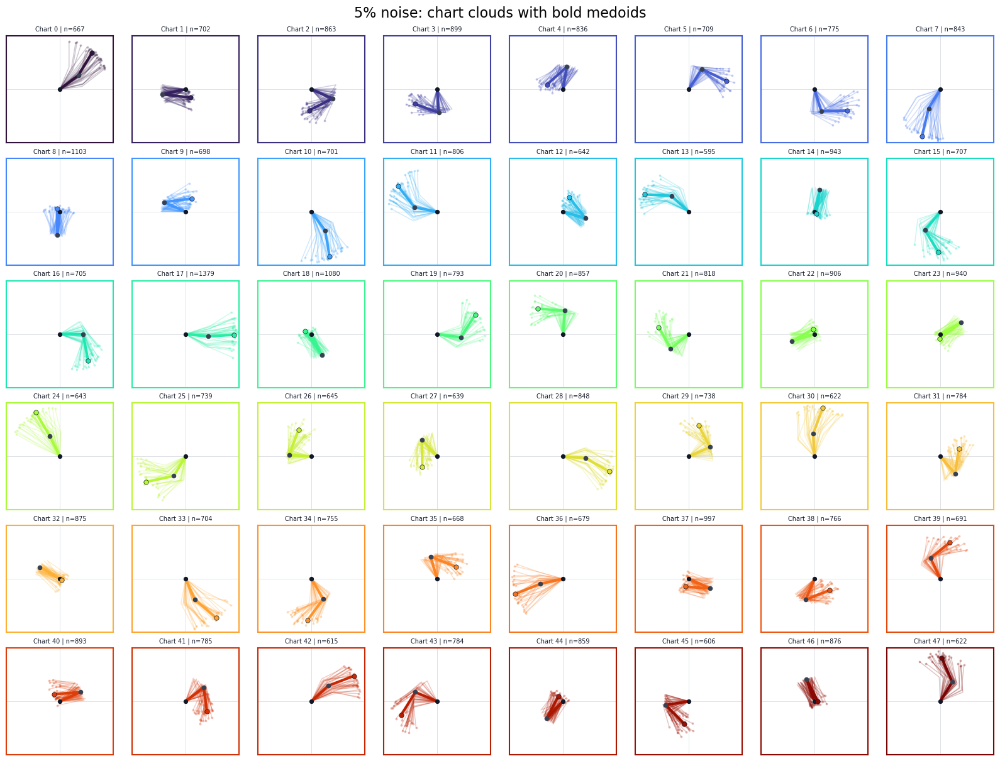

Medoid forward-kinematics consistency: max 16.981 mm
Chart occupancy: min 595, median 770, max 1379 windows


In [4]:
from matplotlib.collections import LineCollection

chart_sizes = np.bincount(atlas["labels"].astype(int), minlength=config.clusters)
medoid_states = np.asarray(atlas["medoid_states"], dtype=float)
chart_colors = plt.cm.turbo(np.linspace(0.0, 1.0, config.clusters))
chart_output_states = H[experiment.pipe.M * experiment.pipe.L:].reshape(
    experiment.pipe.L, experiment.pipe.P, H.shape[1]
)[experiment.pipe.T_INI - 1].T
cloud_members_per_chart = 32
cloud_rng = np.random.default_rng(17)

# Reacher-v5's output geometry is approximately 0.10 m to the elbow and
# 0.11 m from the elbow to the reported fingertip site.
link_1, link_2 = 0.10, 0.11
elbows = link_1 * np.column_stack([medoid_states[:, 0], medoid_states[:, 2]])
fk_fingertips = elbows + link_2 * np.column_stack([medoid_states[:, 8], medoid_states[:, 9]])
stored_fingertips = medoid_states[:, 6:8]
fk_error = np.linalg.norm(fk_fingertips - stored_fingertips, axis=1)

fig, axes = plt.subplots(6, 8, figsize=(16, 12), constrained_layout=True)
for chart_id, ax in enumerate(axes.flat):
    elbow = elbows[chart_id]
    fingertip = stored_fingertips[chart_id]
    color = chart_colors[chart_id]
    member_indices = np.flatnonzero(atlas["labels"] == chart_id)
    sampled_indices = cloud_rng.choice(
        member_indices, size=min(cloud_members_per_chart, member_indices.size), replace=False
    )
    cloud_states = chart_output_states[sampled_indices]
    cloud_elbows = link_1 * np.column_stack([cloud_states[:, 0], cloud_states[:, 2]])
    cloud_fingertips = cloud_states[:, 6:8]
    cloud_segments = np.stack([
        np.zeros_like(cloud_elbows), cloud_elbows, cloud_fingertips
    ], axis=1)
    ax.add_collection(LineCollection(
        cloud_segments, colors=[color], linewidths=1.05, alpha=0.24, zorder=1
    ))
    ax.scatter(cloud_fingertips[:, 0], cloud_fingertips[:, 1], s=7,
               color=color, alpha=0.32, linewidth=0, zorder=1)
    ax.plot([0, elbow[0], fingertip[0]], [0, elbow[1], fingertip[1]],
            color=color, linewidth=3.0, solid_capstyle="round", zorder=3)
    ax.scatter([0], [0], s=18, color="#111827", zorder=3)
    ax.scatter([elbow[0]], [elbow[1]], s=20, color="#374151", zorder=3)
    ax.scatter([fingertip[0]], [fingertip[1]], s=28, color=color,
               edgecolor="#111827", linewidth=0.5, zorder=4)
    ax.axhline(0, color="#d1d5db", linewidth=0.5, zorder=0)
    ax.axvline(0, color="#d1d5db", linewidth=0.5, zorder=0)
    ax.set_xlim(-0.225, 0.225)
    ax.set_ylim(-0.225, 0.225)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Chart {chart_id} | n={chart_sizes[chart_id]}", fontsize=7, color="#111827")
    for spine in ax.spines.values():
        spine.set_color(color)
        spine.set_linewidth(1.5)
fig.suptitle(f"{100*ATLAS_NOISE_RATIO:g}% noise: chart clouds with bold medoids", fontsize=16)
medoid_plot_path = RESULT_ROOT / experiment.level_name(ATLAS_NOISE_RATIO) / "physical48_chart_configuration_clouds.png"
fig.savefig(medoid_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Medoid forward-kinematics consistency: max {1000 * fk_error.max():.3f} mm")
print(f"Chart occupancy: min {chart_sizes.min()}, median {np.median(chart_sizes):.0f}, max {chart_sizes.max()} windows")


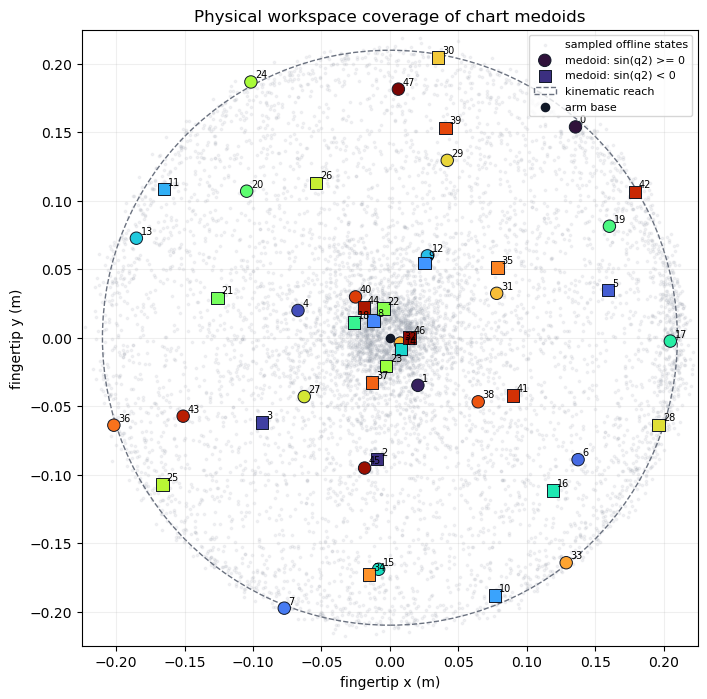

In [5]:
Y_windows = H[experiment.pipe.M * experiment.pipe.L:].reshape(
    experiment.pipe.L, experiment.pipe.P, H.shape[1]
)
offline_fingertips = Y_windows[experiment.pipe.T_INI - 1, 6:8].T
workspace_sample = np.linspace(0, offline_fingertips.shape[0] - 1, 8000, dtype=int)
elbow_up = medoid_states[:, 3] >= 0.0  # sign of sin(q2)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(offline_fingertips[workspace_sample, 0], offline_fingertips[workspace_sample, 1],
           s=3, color="#9ca3af", alpha=0.12, label="sampled offline states")
for mask, marker, label in [(elbow_up, "o", "medoid: sin(q2) >= 0"),
                            (~elbow_up, "s", "medoid: sin(q2) < 0")]:
    ax.scatter(stored_fingertips[mask, 0], stored_fingertips[mask, 1],
               c=chart_colors[mask], marker=marker, s=80, edgecolor="#111827",
               linewidth=0.7, label=label, zorder=3)
for chart_id, (x, y) in enumerate(stored_fingertips):
    ax.annotate(str(chart_id), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
ax.add_patch(plt.Circle((0, 0), link_1 + link_2, fill=False, linestyle="--",
                        color="#6b7280", linewidth=1, label="kinematic reach"))
ax.scatter([0], [0], color="#111827", s=35, label="arm base", zorder=4)
ax.set_aspect("equal")
ax.set_xlim(-0.225, 0.225)
ax.set_ylim(-0.225, 0.225)
ax.set_xlabel("fingertip x (m)")
ax.set_ylabel("fingertip y (m)")
ax.set_title("Physical workspace coverage of chart medoids")
ax.grid(alpha=0.2)
ax.legend(loc="upper right", fontsize=8)
workspace_plot_path = RESULT_ROOT / experiment.level_name(ATLAS_NOISE_RATIO) / "atlas_workspace_coverage.png"
fig.savefig(workspace_plot_path, dpi=160, bbox_inches="tight")
plt.show()

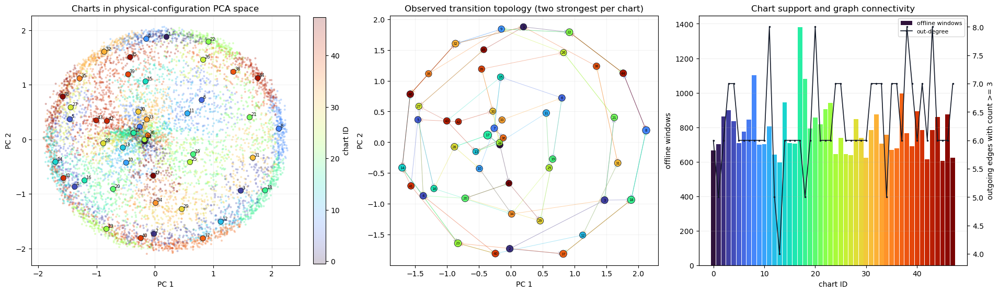

Active clustering coordinates: 6
PCA variance captured: 38.1%
Directed routing edges retained by the controller: 302
Outgoing-degree range: 4 to 8


In [6]:
from sklearn.decomposition import PCA

clustering_features, _, _ = experiment.routed.behavioral_features(
    H,
    config.clustering_input_weight,
    config.clustering_feature_mode,
    config.clustering_configuration_weight,
    config.clustering_velocity_weight,
    config.clustering_fingertip_weight,
)
active_feature_mask = clustering_features.std(axis=0) > 1e-10
gate_features = clustering_features[:, active_feature_mask]
gate_centers = atlas["centers"][:, active_feature_mask]
pca = PCA(n_components=2)
gate_pca = pca.fit_transform(gate_features)
center_pca = pca.transform(gate_centers)
history_sample = np.linspace(0, gate_pca.shape[0] - 1, 8000, dtype=int)
transition_counts = np.asarray(atlas["transition_counts"], dtype=int)
edge_mask = transition_counts >= config.edge_count_threshold
np.fill_diagonal(edge_mask, False)
out_degree = edge_mask.sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)
scatter = axes[0].scatter(gate_pca[history_sample, 0], gate_pca[history_sample, 1],
                          c=atlas["labels"][history_sample], cmap="turbo",
                          vmin=-0.5, vmax=config.clusters - 0.5, s=4, alpha=0.22)
axes[0].scatter(center_pca[:, 0], center_pca[:, 1], c=chart_colors, s=55,
                edgecolor="#111827", linewidth=0.6)
for chart_id, (x, y) in enumerate(center_pca):
    axes[0].annotate(str(chart_id), (x, y), xytext=(2, 2),
                     textcoords="offset points", fontsize=6)
axes[0].set_title("Charts in physical-configuration PCA space")
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")
axes[0].grid(alpha=0.15)
fig.colorbar(scatter, ax=axes[0], label="chart ID", fraction=0.046)

# Show the two strongest observed outgoing transitions per chart. The router
# itself retains every edge meeting the count threshold.
for source in range(config.clusters):
    destinations = np.flatnonzero(edge_mask[source])
    if destinations.size:
        strongest = destinations[np.argsort(transition_counts[source, destinations])[-2:]]
        for destination in strongest:
            strength = transition_counts[source, destination]
            axes[1].annotate("", xy=center_pca[destination], xytext=center_pca[source],
                             arrowprops=dict(arrowstyle="->", color=chart_colors[source],
                                             alpha=min(0.75, 0.18 + strength / 250),
                                             linewidth=0.7))
node_sizes = 35 + 90 * chart_sizes / chart_sizes.max()
axes[1].scatter(center_pca[:, 0], center_pca[:, 1], c=chart_colors, s=node_sizes,
                edgecolor="#111827", linewidth=0.6, zorder=3)
for chart_id, (x, y) in enumerate(center_pca):
    axes[1].annotate(str(chart_id), (x, y), ha="center", va="center", fontsize=5, zorder=4)
axes[1].set_title("Observed transition topology (two strongest per chart)")
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")
axes[1].grid(alpha=0.15)

chart_ids = np.arange(config.clusters)
axes[2].bar(chart_ids, chart_sizes, color=chart_colors, width=0.9, label="offline windows")
axes[2].set_xlabel("chart ID")
axes[2].set_ylabel("offline windows")
axes[2].set_title("Chart support and graph connectivity")
axes[2].grid(axis="y", alpha=0.2)
degree_axis = axes[2].twinx()
degree_axis.plot(chart_ids, out_degree, color="#111827", linewidth=1.2,
                 marker=".", markersize=3, label="out-degree")
degree_axis.set_ylabel("outgoing edges with count >= 3")
lines_1, labels_1 = axes[2].get_legend_handles_labels()
lines_2, labels_2 = degree_axis.get_legend_handles_labels()
axes[2].legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right", fontsize=8)

topology_plot_path = RESULT_ROOT / experiment.level_name(ATLAS_NOISE_RATIO) / "physical48_atlas_topology.png"
fig.savefig(topology_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print("Active clustering coordinates:", gate_features.shape[1])
print("PCA variance captured:", f"{100 * pca.explained_variance_ratio_.sum():.1f}%")
print("Directed routing edges retained by the controller:", int(edge_mask.sum()))
print("Outgoing-degree range:", int(out_degree.min()), "to", int(out_degree.max()))


### How to Read These Views

The workspace panel shows noisy offline fingertip coverage; the dashed circle is
the nominal kinematic reach, not a constraint on noisy measurements. PCA is a
two-dimensional visualization only. The graph panel draws the two strongest
outgoing edges per chart, while control retains all edges meeting the count
threshold of three. Forward-kinematics inconsistency is an expected diagnostic
of independent output-channel noise, not a correction used by control.


## 3. Result and Fairness Audit

The zero-noise condition uses the same observer wrapper as the noisy conditions.
Its sensor outputs must exactly equal truth when noise is zero. All noise levels
use the same clean source data and noise seeds, with separate noisy atlases.
We verify rank-59 bases, noise calibration, true-state error, and source hashes.
The archived rank-60 results are not reused for this new configuration.


In [7]:
zero_matches = 0
for seed in SEEDS:
    zero_path = RESULT_ROOT / experiment.level_name(0) / f"seed{seed}_control_results.npz"
    with np.load(zero_path, allow_pickle=True) as zero:
        np.testing.assert_array_equal(zero["sensor_true"], zero["sensor_measured"])
        zero_matches += 1
atlas_rows = []
for ratio, payload in payloads.items():
    artifact = payload["artifact"]
    assert artifact["overlap_consistency_verified"] and artifact["applied_inputs_unchanged"]
    assert artifact["offline_unique_samples"] == 40000
    from candidate_goal_routing_experiment import file_digest
    for name, digest in artifact["artifact_sha256"].items():
        assert file_digest(RESULT_ROOT / experiment.level_name(ratio) / name) == digest
    with np.load(RESULT_ROOT / experiment.level_name(ratio) / "chart_cache.npz") as cache:
        assert cache["basis"].shape == (48, 144, 59)
        assert not np.any(cache["offset"])
    if ratio:
        np.testing.assert_allclose(artifact["empirical_offline_power_nsr"], ratio**2, rtol=.04)
    online_noise = []
    for row in payload["results"]:
        path = RESULT_ROOT / experiment.level_name(ratio) / f"seed{row['seed']}_control_results.npz"
        with np.load(path, allow_pickle=True) as trace:
            np.testing.assert_array_equal(trace["sensor_measured"][-320:], trace["y_measured"])
            np.testing.assert_array_equal(trace["sensor_true"][-320:], trace["y"])
            np.testing.assert_allclose(trace["distance"], np.linalg.norm(trace["y"][:, 6:8]-row["exact_target_xy"], axis=1))
            assert len(trace["sensor_true"]) == 323
            rng = np.random.default_rng(np.random.SeedSequence([experiment.noise.ONLINE_NOISE_SEED, row["seed"]]))
            expected_noise = rng.normal(size=trace["sensor_true"].shape)*np.array(artifact["noise_std"])
            np.testing.assert_allclose(trace["sensor_measured"]-trace["sensor_true"], expected_noise, rtol=0, atol=1e-14)
            online_noise.append(trace["sensor_measured"]-trace["sensor_true"])
    realized = np.sqrt(np.mean(np.concatenate(online_noise)**2, axis=0))/np.array(artifact["signal_std"])
    if ratio:
        np.testing.assert_allclose(realized, ratio, rtol=.03)
    else:
        np.testing.assert_array_equal(realized, np.zeros(10))
    sizes = artifact["chart_sizes"]
    atlas_rows.append({"Noise SD (%)": 100*ratio, "Charts": len(sizes), "Smallest chart": min(sizes),
                       "Largest chart": max(sizes), "Unreachable chart pairs": artifact["unreachable_chart_pairs"],
                       "Min observed online SD ratio (%)": 100*realized.min(),
                       "Max observed online SD ratio (%)": 100*realized.max(),
                       "Offline fit (s)": artifact["offline_preparation_s"]["chart_fit"],
                       "Offline bases/routes (s)": artifact["offline_preparation_s"]["svd_cache_and_routes"]})
print(f"Zero-noise sensor outputs exactly match truth for {zero_matches}/100 seeds.")
print(f"All chart hashes, rank-59 bases, and {len(frame)} sensor-noise streams verified.")
audit = experiment.routed.audit_iid_library(np.load(experiment.baseline.DATA_PATH, mmap_mode="r"), eval_seeds=SEEDS)
assert audit["offline_stabilized_episode_count"] == 0
display(pd.Series({"offline stabilized episodes": audit["offline_stabilized_episode_count"],
    "minimum selected source-target separation (m)": frame.minimum_selected_goal_source_separation.min(),
    "fitted dynamics / contextual rescue": "none", "evaluation": "true simulator outputs"}))
display(pd.DataFrame(atlas_rows).set_index("Noise SD (%)").round(3))


Zero-noise sensor outputs exactly match truth for 100/100 seeds.
All chart hashes, rank-59 bases, and 700 sensor-noise streams verified.


offline stabilized episodes                                           0
minimum selected source-target separation (m)                  0.060324
fitted dynamics / contextual rescue                                none
evaluation                                       true simulator outputs
dtype: object

,Charts,Smallest chart,Largest chart,Unreachable chart pairs,Min observed online SD ratio (%),Max observed online SD ratio (%),Offline fit (s),Offline bases/routes (s)
Noise SD (%),,,,,,,,
0.0,48,558,1292,0,0.000,0.000,0.002,0.137
1.0,48,533,1653,0,0.992,1.008,0.102,0.138
2.0,48,583,1394,0,1.984,2.016,0.084,0.179
3.0,48,530,1345,0,2.976,3.024,0.172,0.223
4.0,48,484,1372,0,3.968,4.032,0.118,0.176
5.0,48,595,1379,0,4.961,5.040,0.152,0.167
10.0,48,472,1220,0,9.921,10.080,0.144,0.184


## 4. Results and Tracking Accuracy

Strict success requires **mean true error below 1 cm and maximum true error below
2 cm in both final-30 and final-100 windows**. The horizons, run length, QP weights,
input limits, coefficient-bound rule, and success thresholds are fixed across
noise levels. Rank is 59 and coefficient regularization is 0.05 throughout.
Unsolved QPs retain the baseline's zero-action handling and are not discarded.


,Successes,Success rate (%),Median final-100 true error (mm),P90 final-100 true error (mm),Mean tail time below 10 mm (%),Unsolved QP steps
Noise SD (%),,,,,,
0.0,97,97.0,2.045,4.431,97.00,0
1.0,88,88.0,3.163,10.640,89.28,0
2.0,87,87.0,4.660,10.198,87.77,0
3.0,60,60.0,7.532,17.639,63.51,0
4.0,62,62.0,7.643,15.340,66.06,0
5.0,41,41.0,10.599,21.122,48.15,0
10.0,2,2.0,16.468,30.721,22.34,0


,Power NSR,Successes,Trials,Success rate (%),Median final-100 true error (mm),P90 final-100 true error (mm),Median tail RMSE (mm),Median within-seed tail SD (mm),Mean tail time below 10 mm (%),Mean tail time below 20 mm (%),Unsolved QP steps,Median goal-sample switches
Noise SD (%),,,,,,,,,,,,
0.0,0.000,97,100,97.0,2.045,4.431,2.045,0.000,97.00,98.00,0,0.0
1.0,0.000,88,100,88.0,3.163,10.640,3.260,0.864,89.28,94.35,0,0.0
2.0,0.000,87,100,87.0,4.660,10.198,4.789,1.181,87.77,94.96,0,0.0
3.0,0.001,60,100,60.0,7.532,17.639,7.983,2.064,63.51,90.78,0,0.0
4.0,0.002,62,100,62.0,7.643,15.340,8.355,2.239,66.06,94.46,0,0.0
5.0,0.003,41,100,41.0,10.599,21.122,11.294,2.642,48.15,85.64,0,0.0
10.0,0.010,2,100,2.0,16.468,30.721,18.096,6.649,22.34,62.35,0,3.5


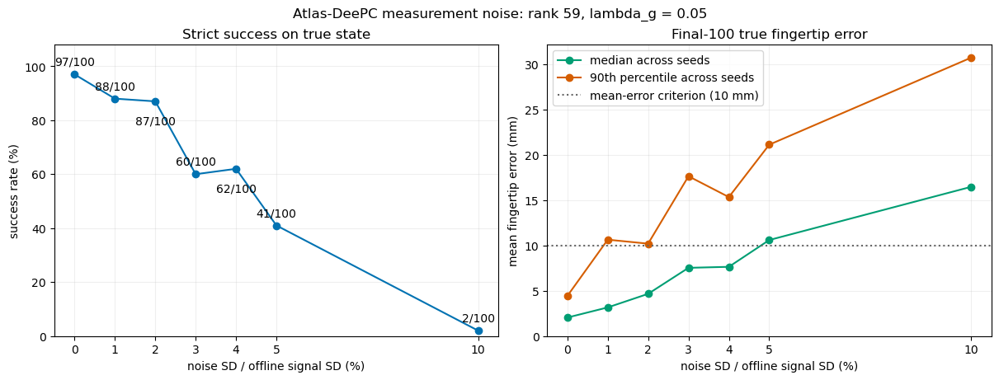

,Repaired,Regressed
Noise SD (%),,
1.0,1,10
2.0,0,10
3.0,0,37
4.0,1,36
5.0,0,56
10.0,0,95


,Repaired,Regressed,Repaired seeds,Regressed seeds
Noise SD (%),,,,
1.0,1,10,[252],"[229, 236, 251, 255, 274, 281, 283, 287, 290, 298]"
2.0,0,10,[],"[222, 231, 236, 259, 264, 277, 280, 284, 296, 298]"
3.0,0,37,[],"[216, 217, 219, 221, 222, 226, 230, 231, 232, 236, 240, 241, 247, 251, 254, 255, 256, 260, 262, 264, 267, 269, 271, 275, 282, 284, 288, 289, 290, 291, 294, 296, 298, 302, 304, 309, 310]"
4.0,1,36,[299],"[214, 216, 217, 227, 231, 232, 234, 237, 246, 254, 255, 257, 263, 264, 267, 269, 270, 271, 272, 273, 277, 278, 279, 280, 289, 292, 293, 296, 298, 300, 301, 302, 306, 308, 309, 310]"
5.0,0,56,[],"[212, 214, 216, 222, 225, 228, 229, 231, 232, 234, 236, 237, 239, 242, 246, 247, 248, 249, 250, 251, 254, 255, 257, 258, 260, 261, 262, 263, 264, 267, 270, 272, 274, 276, 277, 279, 280, 281, 283, 284, 285, 286, 287, 289, 290, 292, 293, 294, 297, 298, 300, 302, 303, 305, 307, 310]"
10.0,0,95,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 235, 236, 237, 238, 239, 240, 242, 243, 244, 246, 247, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"


In [8]:
summary_rows = []
for ratio in SD_RATIOS:
    rows = frame[frame.noise_sd_ratio == ratio]
    summary_rows.append({"Noise SD (%)": 100*ratio, "Power NSR": ratio**2,
                         "Successes": int(rows.strict_success.sum()), "Trials": len(rows),
                         "Success rate (%)": 100*rows.strict_success.mean(),
                         "Median final-100 true error (mm)": 1000*rows.mean_last_100.median(),
                         "P90 final-100 true error (mm)": 1000*rows.mean_last_100.quantile(.9),
                         "Median tail RMSE (mm)": rows.tail_rmse_mm.median(),
                         "Median within-seed tail SD (mm)": rows.tail_std_mm.median(),
                         "Mean tail time below 10 mm (%)": rows.tail_within_10_pct.mean(),
                         "Mean tail time below 20 mm (%)": rows.tail_within_20_pct.mean(),
                         "Unsolved QP steps": int(rows.unsolved_steps.sum()),
                         "Median goal-sample switches": rows.goal_sample_switches.median()})
summary = pd.DataFrame(summary_rows).set_index("Noise SD (%)")
display(summary[["Successes", "Success rate (%)", "Median final-100 true error (mm)",
                 "P90 final-100 true error (mm)", "Mean tail time below 10 mm (%)",
                 "Unsolved QP steps"]].round(3))
display(HTML("<details><summary>All error summary statistics</summary>" + summary.round(3).to_html() + "</details>"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
fig.suptitle("Atlas-DeePC measurement noise: rank 59, lambda_g = 0.05")
axes[0].plot(percent, summary["Success rate (%)"], "o-", color="#0072B2")
for x, rate, count in zip(percent, summary["Success rate (%)"], summary.Successes):
    offset = (0, -20) if x in (2, 4) else (0, 8)
    axes[0].annotate(f"{count}/100", (x, rate), xytext=offset, textcoords="offset points", ha="center")
axes[0].set(ylim=(0, 108), title="Strict success on true state", ylabel="success rate (%)")
for column, color, label in [("Median final-100 true error (mm)", "#009E73", "median across seeds"),
                              ("P90 final-100 true error (mm)", "#D55E00", "90th percentile across seeds")]:
    axes[1].plot(percent, summary[column], "o-", color=color, label=label)
axes[1].axhline(10, color="#666666", linestyle=":", label="mean-error criterion (10 mm)")
axes[1].set(ylim=(0, None), title="Final-100 true fingertip error", ylabel="mean fingertip error (mm)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("noise SD / offline signal SD (%)")
    ax.set_xticks(percent)
    ax.grid(alpha=.2)
fig.savefig(RESULT_ROOT / "noise_success_and_accuracy.png", dpi=170)
plt.show()
(RESULT_ROOT / "noise_report.json").write_text(summary.reset_index().to_json(orient="records", indent=2))
clean = frame[frame.noise_sd_ratio == 0].set_index("seed")
paired = []
for ratio in SD_RATIOS[1:]:
    noisy = frame[frame.noise_sd_ratio == ratio].set_index("seed").loc[clean.index]
    repaired = noisy.index[noisy.strict_success & ~clean.strict_success].tolist()
    regressed = noisy.index[~noisy.strict_success & clean.strict_success].tolist()
    paired.append({"Noise SD (%)": 100*ratio, "Repaired": len(repaired), "Regressed": len(regressed),
                   "Repaired seeds": repaired, "Regressed seeds": regressed})
paired = pd.DataFrame(paired).set_index("Noise SD (%)")
display(paired[["Repaired", "Regressed"]])
display(HTML("<details><summary>Paired seed lists</summary>" + paired.to_html() + "</details>"))


### Error Distributions and Time Near the Target

Each seed contributes equally. The CDF shows the distribution of each seed's
**final-100 mean true fingertip error**, first over its complete range and then
zoomed to 0--30 mm. A CDF value at 10 mm is a mean-error pass fraction, **not**
the stricter success rate above.

The lower panels show every seed: the fraction of its final 100 steps below
10 mm, and the temporal standard deviation of its fingertip-error magnitude.
Low temporal SD alone does not imply accuracy: an arm stuck away from the target
can have constant error. Boxes show the median and interquartile range; whiskers
span the 5th--95th percentiles, and dots include all 100 seeds, including outliers.
These are empirical distributions, not confidence intervals.


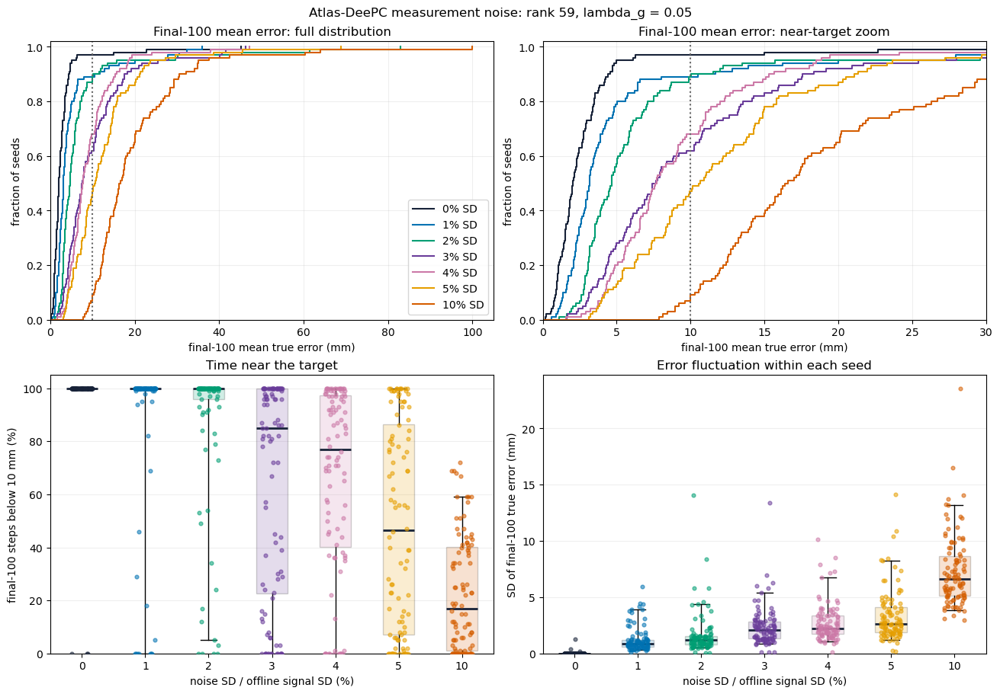

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle("Atlas-DeePC measurement noise: rank 59, lambda_g = 0.05")
for ratio, color in zip(SD_RATIOS, COLORS):
    values = np.sort(1000*frame.loc[frame.noise_sd_ratio == ratio, "mean_last_100"].to_numpy())
    x = np.r_[0, values]
    cumulative = np.r_[0, np.arange(1, len(values)+1)/len(values)]
    for ax in axes[0]:
        ax.step(x, cumulative, where="post", color=color, label=f"{100*ratio:g}% SD")
for ax, title in zip(axes[0], ["Final-100 mean error: full distribution", "Final-100 mean error: near-target zoom"]):
    ax.axvline(10, color="#666666", linestyle=":")
    ax.set(xlim=(0, None), ylim=(0, 1.02), xlabel="final-100 mean true error (mm)",
           ylabel="fraction of seeds", title=title)
    ax.grid(alpha=.2)
axes[0, 1].set_xlim(0, 30)
axes[0, 0].legend(loc="lower right")
for ax, metric, title, ylabel in [
    (axes[1, 0], "tail_within_10_pct", "Time near the target", "final-100 steps below 10 mm (%)"),
    (axes[1, 1], "tail_std_mm", "Error fluctuation within each seed", "SD of final-100 true error (mm)")]:
    groups = [frame.loc[frame.noise_sd_ratio == r, metric].to_numpy() for r in SD_RATIOS]
    bp = ax.boxplot(groups, positions=np.arange(len(SD_RATIOS)), widths=.5, patch_artist=True, whis=(5, 95), showfliers=False,
                    medianprops={"color": "#172238", "linewidth": 2})
    jitter = np.random.default_rng(710).uniform(-.16, .16, 100)
    for i, (values, color, box) in enumerate(zip(groups, COLORS, bp["boxes"])):
        box.set(facecolor=color, alpha=.18)
        ax.scatter(i+jitter, values, s=12, color=color, alpha=.55, zorder=3)
    ax.set(ylim=(0, 105) if metric.endswith("pct") else (0, None),
           xlabel="noise SD / offline signal SD (%)", ylabel=ylabel, title=title)
    ax.set_xticks(np.arange(len(SD_RATIOS)), [f"{100*r:g}" for r in SD_RATIOS])
    ax.grid(axis="y", alpha=.2)
fig.savefig(RESULT_ROOT / "noise_error_distributions.png", dpi=170)
plt.show()


### 4.1. Computation Time by Module

Local wall-clock timings use four rollout workers and one numerical-library thread
per worker. Five initial steps are excluded per rollout; there is no separate
warm-up. This shared-computer run is not an isolated hardware benchmark. The
existing control-loop timers exclude simulator stepping and sensor-noise generation.
QP time includes problem construction and solve. Chart fitting and SVD are offline.
Levels were collected in separate batches; these are descriptive timings rather
than a controlled cross-level speed comparison.
The stacked plot uses means, which add to the mean total. Median and p99 module
plots are unstacked because module percentiles do not add to total percentiles.


mean_ms  median_ms   p99_ms
Noise SD (%) module                                                
0.0          QP construction and solve   37.721     34.448   80.416
             Total online control        37.852     34.574   80.605
1.0          QP construction and solve   40.445     36.224   97.076
             Total online control        40.582     36.346   97.267
2.0          QP construction and solve   39.319     35.977   88.075
             Total online control        39.449     36.099   88.416
3.0          QP construction and solve   46.713     43.979   86.486
             Total online control        46.859     44.122   86.769
4.0          QP construction and solve   46.344     43.741   85.585
             Total online control        46.489     43.879   85.733
5.0          QP construction and solve   40.380     36.284   98.794
             Total online control        40.520     36.408   99.482
10.0         QP construction and solve   42.612     38.108  106.452
             Total online control        42.756     38.244  106.572

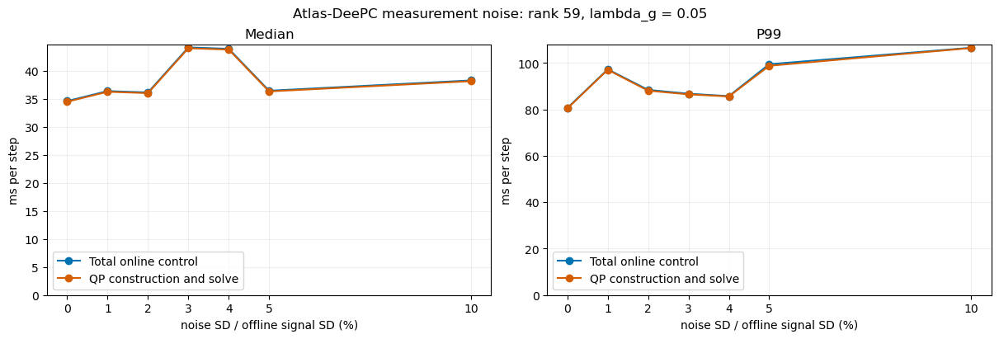

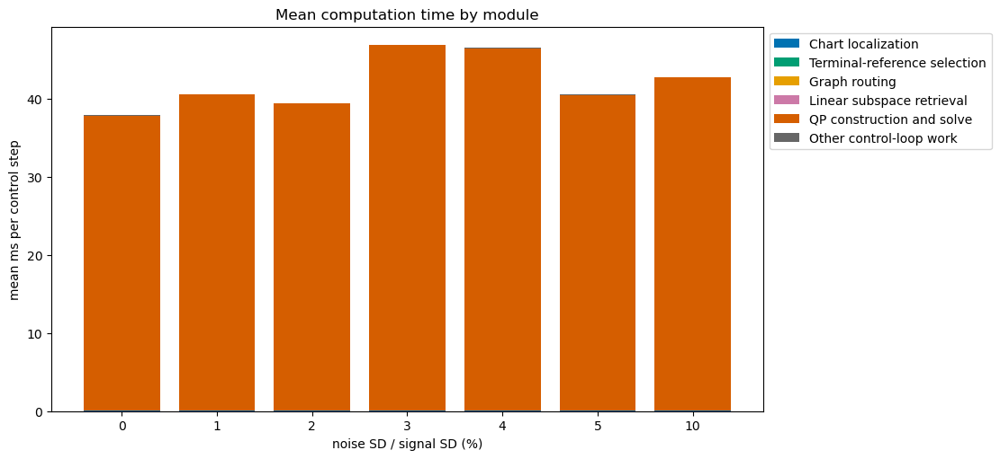

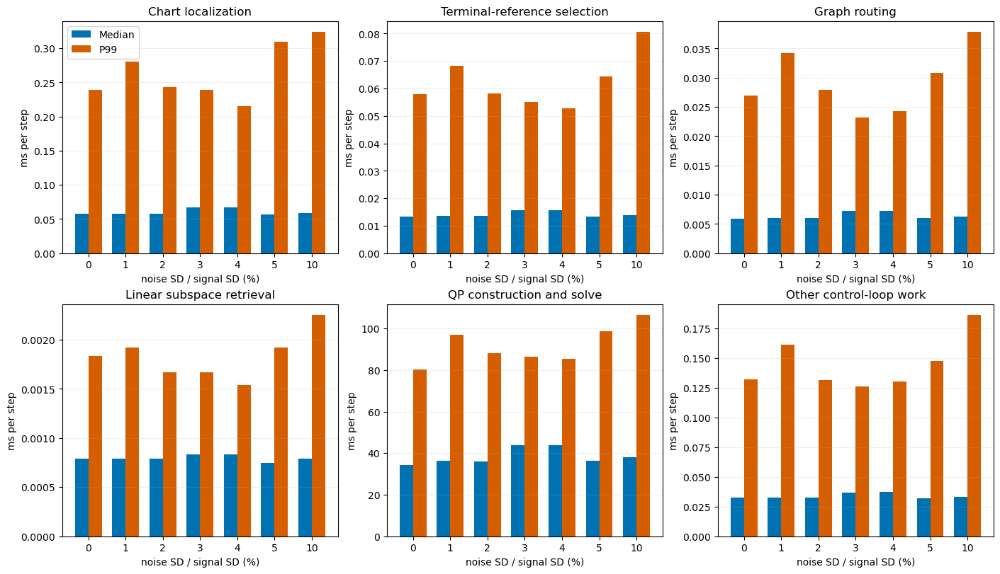

,One-time terminal candidate search: mean (ms),One-time terminal candidate search: median (ms),One-time terminal candidate search: p95 (ms)
Noise SD (%),,,
0.0,13.574,12.830,23.350
1.0,14.449,14.110,26.092
2.0,9.631,7.819,16.270
3.0,13.842,14.657,24.468
4.0,13.781,13.303,25.866
5.0,14.613,13.789,28.550
10.0,17.048,14.869,28.014


In [10]:
timing_rows = []
for ratio, payload in payloads.items():
    assert payload["timing"]["timed_steps"] == 31500
    timing_rows.extend({"Noise SD (%)": 100*ratio, **r} for r in payload["timing"]["modules"])
timing = pd.DataFrame(timing_rows)
display(timing[timing.module.isin(["Total online control", "QP construction and solve"])]
        .set_index(["Noise SD (%)", "module"])[["mean_ms", "median_ms", "p99_ms"]].round(3))
display(HTML("<details><summary>All computation modules</summary>" + timing.set_index(["Noise SD (%)", "module"])
             [["mean_ms", "median_ms", "p95_ms", "p99_ms"]].round(4).to_html() + "</details>"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
fig.suptitle("Atlas-DeePC measurement noise: rank 59, lambda_g = 0.05")
for ax, metric, label in zip(axes, ["median_ms", "p99_ms"], ["Median", "P99"]):
    for module, color in [("Total online control", "#0072B2"), ("QP construction and solve", "#D55E00")]:
        rows = timing[timing.module == module]
        ax.plot(rows["Noise SD (%)"], rows[metric], "o-", label=module, color=color)
    ax.set(ylim=(0, None), xlabel="noise SD / offline signal SD (%)", ylabel="ms per step", title=label)
    ax.set_xticks(percent)
    ax.grid(alpha=.2)
    ax.legend()
fig.savefig(RESULT_ROOT / "noise_computation_time.png", dpi=170)
plt.show()
modules = [m for m in timing.module.unique() if m != "Total online control"]
module_colors = ["#0072B2", "#009E73", "#E69F00", "#CC79A7", "#D55E00", "#666666"]
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
bottom = np.zeros(len(SD_RATIOS))
for module, color in zip(modules, module_colors):
    values = timing[timing.module == module].set_index("Noise SD (%)").loc[percent, "mean_ms"].to_numpy()
    ax.bar(np.arange(len(SD_RATIOS)), values, bottom=bottom, color=color, label=module)
    bottom += values
ax.set(ylim=(0, None), ylabel="mean ms per control step", xlabel="noise SD / signal SD (%)",
       title="Mean computation time by module")
ax.set_xticks(np.arange(len(SD_RATIOS)), [f"{x:g}" for x in percent])
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.savefig(RESULT_ROOT / "noise_timing_mean_modules.png", dpi=170)
plt.show()
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for ax, module in zip(axes.flat, modules):
    rows = timing[timing.module == module].set_index("Noise SD (%)").loc[percent]
    ax.bar(np.arange(len(SD_RATIOS))-.18, rows.median_ms, width=.36, color="#0072B2", label="Median")
    ax.bar(np.arange(len(SD_RATIOS))+.18, rows.p99_ms, width=.36, color="#D55E00", label="P99")
    ax.set(ylim=(0, None), title=module, ylabel="ms per step", xlabel="noise SD / signal SD (%)")
    ax.set_xticks(np.arange(len(SD_RATIOS)), [f"{x:g}" for x in percent])
    ax.grid(axis="y", alpha=.2)
axes.flat[0].legend()
fig.savefig(RESULT_ROOT / "noise_timing_module_percentiles.png", dpi=170)
plt.show()
display(pd.DataFrame([{"Noise SD (%)": 100*r, **payloads[r]["timing"]["one_time_goal_setup_ms"]}
                      for r in SD_RATIOS]).set_index("Noise SD (%)")
        .rename(columns=lambda c: f"One-time terminal candidate search: {c} (ms)").round(3))


## 5. Diagnostic Trajectories: Twelve Seeds

Twelve fixed seeds are shown at every noise level, expanding the previous three
examples. They are fixed before completing this rerun, not chosen for favorable
outcomes. The first figure **zooms to 0--30 mm**, emphasizing the 10 mm criterion.
Small triangles at the upper boundary flag samples outside the zoom; they are
not substituted error values. The second figure retains the full vertical range.
The shaded final-100 window is the main evaluation period. All curves show true
fingertip error, with no smoothing or rollout truncation.


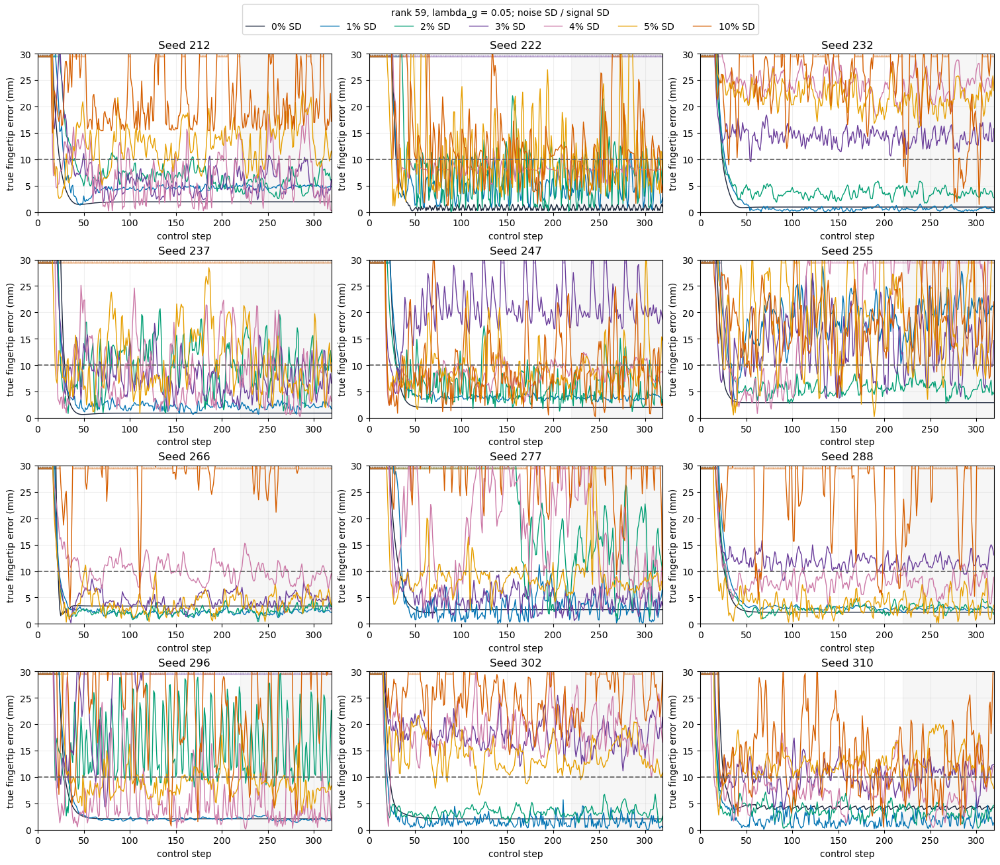

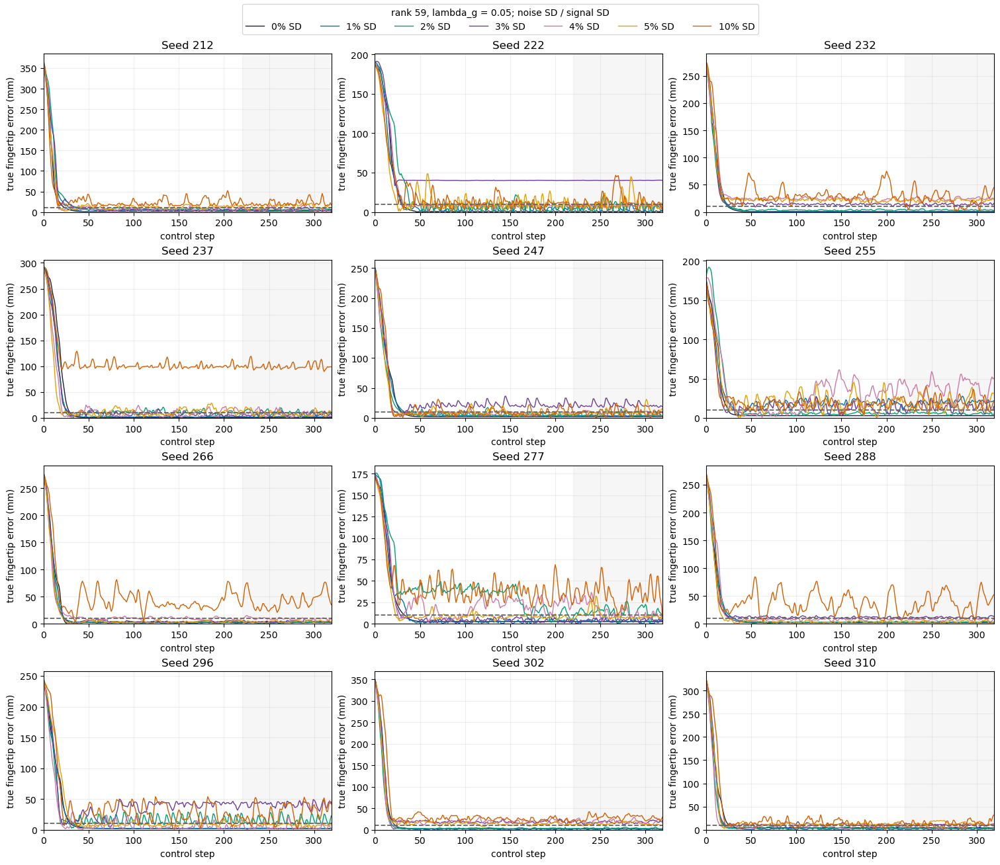

Noise SD (%),0.0,1.0,2.0,3.0,4.0,5.0,10.0
seed,,,,,,,
212,1.940,4.775,5.466,5.950,7.352,13.980,21.642
222,0.773,5.599,7.099,40.179,8.101,11.445,14.122
232,0.945,0.588,3.650,14.151,24.116,21.327,23.482
237,0.912,2.186,9.898,7.379,7.760,8.863,99.996
247,1.969,3.803,6.136,21.708,9.043,9.502,8.460
255,2.903,19.988,5.806,13.397,38.009,17.927,20.083
266,3.379,2.224,2.766,4.483,9.474,4.221,42.411
277,2.705,3.198,13.497,4.246,14.899,9.898,34.880
288,2.207,2.898,3.093,11.637,7.701,3.741,37.527


In [11]:
EXAMPLE_SEEDS = [212, 222, 232, 237, 247, 255, 266, 277, 288, 296, 302, 310]
for zoom in (True, False):
    fig, axes = plt.subplots(4, 3, figsize=(15, 13), constrained_layout=True)
    for ax, seed in zip(axes.flat, EXAMPLE_SEEDS):
        for ratio, color in zip(SD_RATIOS, COLORS):
            error = trace_errors[ratio, seed]
            ax.plot(error, color=color, label=f"{100*ratio:g}% SD", linewidth=1)
            if zoom:
                outside = np.flatnonzero(error > 30)
                ax.scatter(outside, np.full(len(outside), 29.6), marker="^", s=8,
                           color=color, alpha=.25, linewidths=0)
        ax.axvspan(220, 319, color="#666666", alpha=.06)
        ax.axhline(10, color="#666666", linestyle="--", linewidth=1.3)
        ax.set(ylim=(0, 30) if zoom else (0, None), xlim=(0, 319),
               xlabel="control step", ylabel="true fingertip error (mm)", title=f"Seed {seed}")
        if zoom:
            ax.set_yticks([0, 5, 10, 15, 20, 25, 30])
        ax.grid(alpha=.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=len(SD_RATIOS),
               title="rank 59, lambda_g = 0.05; noise SD / signal SD")
    suffix = "zoom" if zoom else "full"
    fig.savefig(RESULT_ROOT / f"noise_example_traces_{suffix}.png", dpi=150)
    plt.show()
example_table = frame[frame.seed.isin(EXAMPLE_SEEDS)].copy()
example_table["Final-100 mean true error (mm)"] = 1000*example_table.mean_last_100
example_table["Noise SD (%)"] = 100*example_table.noise_sd_ratio
display(example_table.pivot(index="seed", columns="Noise SD (%)",
                            values="Final-100 mean true error (mm)").round(3))


## 6. Slowed Atlas-Routing Dashboards

These six dashboards replay **saved rank-59, $\lambda_g=0.05$ rollouts**, not new simulations:

- **Seed 212, 1% versus 5%.**
- **Seed 222, 1% versus 5%.**
- **Seed 237, 2% versus 10%.**

These are the same diagnostic examples as before; all outcome labels and error
statistics below are recomputed from the new experiment, not copied from old videos.

The dark arm is simulator truth; the gray cross is the noisy fingertip reading.
The red error curve is true error, while the gray curve is sensed error. Reference
postures and chart routes use the matching noisy offline atlas. Noisy references
and predictions need not be kinematically consistent.

All **320 steps** remain visible, including late fluctuations. Playback uses the
same **0.25x dashboard-speed convention** as the earlier videos (relative to one
sample per frame at 20 fps, not simulator real time). Interpolation is for display
only; the controller did not smooth its measurements or actions. The error panel
zooms near the target; initial errors above its limit are outside that panel, but
their magnitude remains in the header and the full-range plots in Section 5.



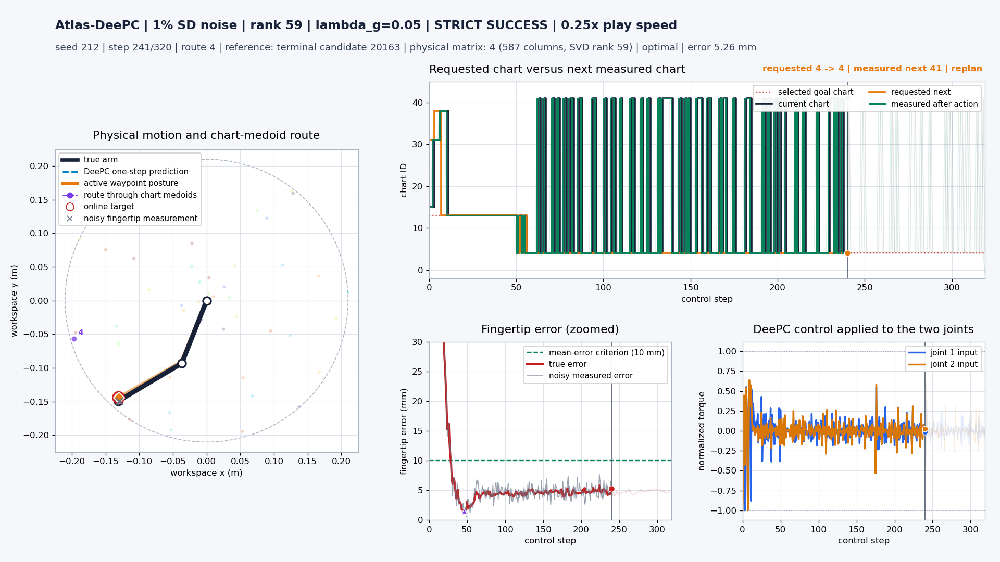
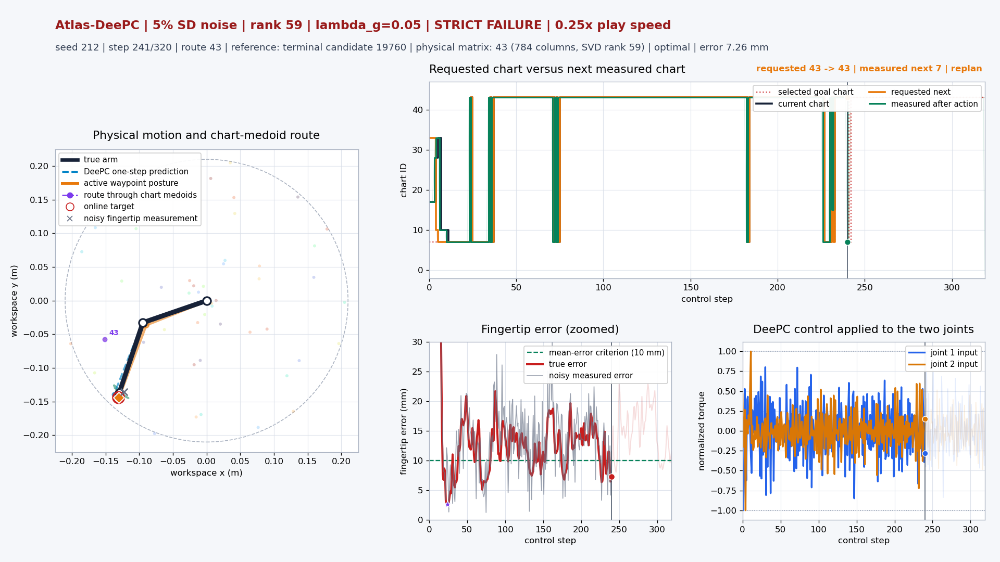


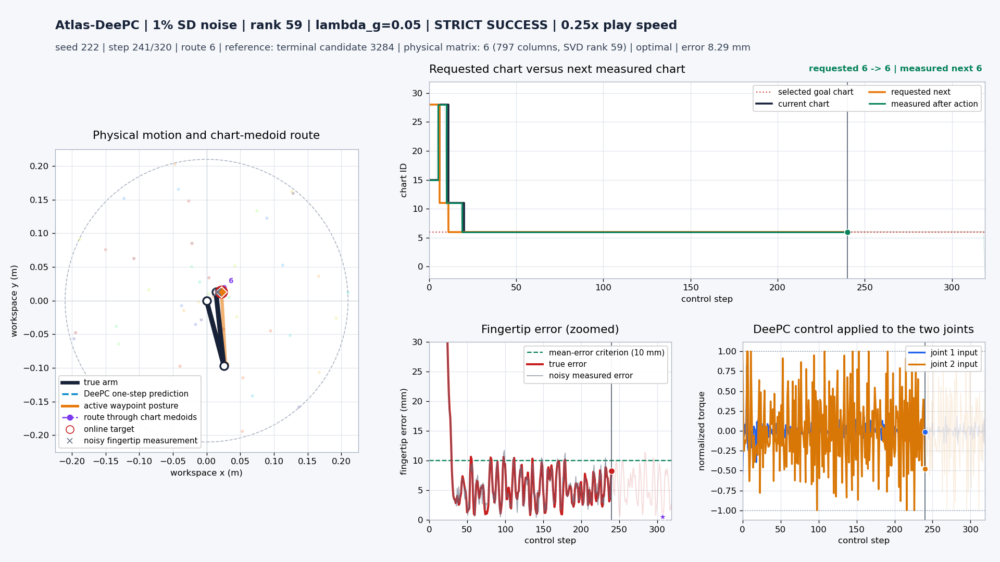
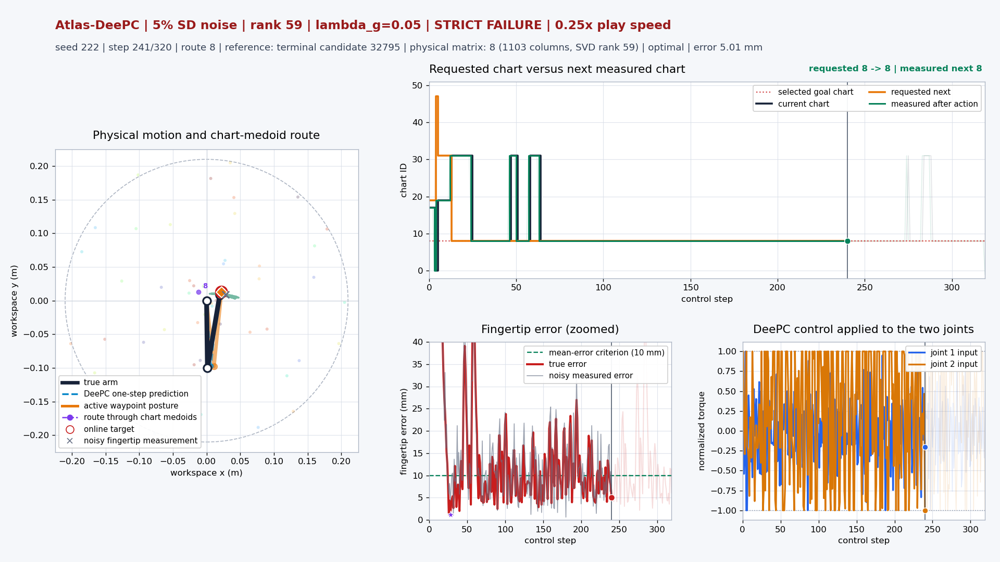


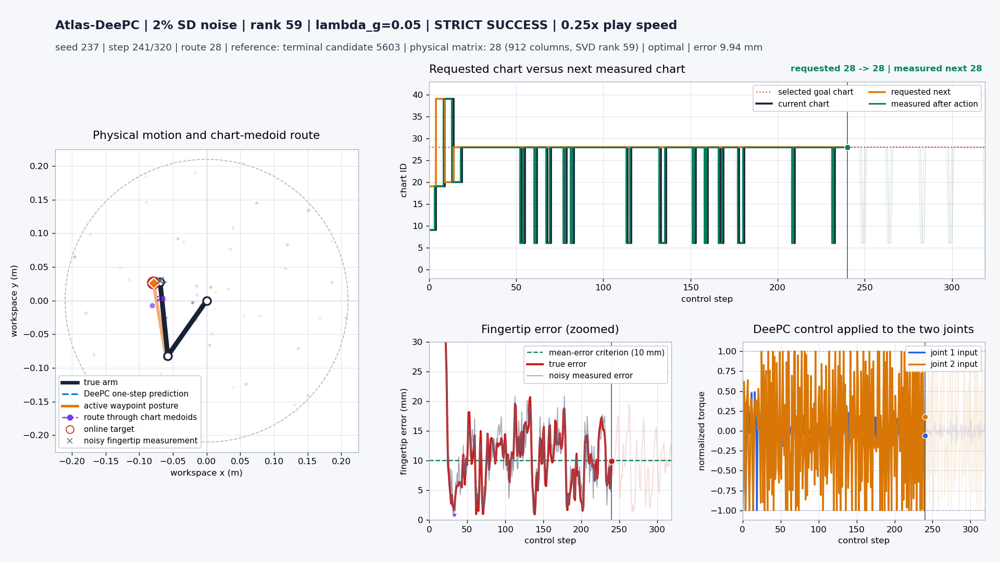
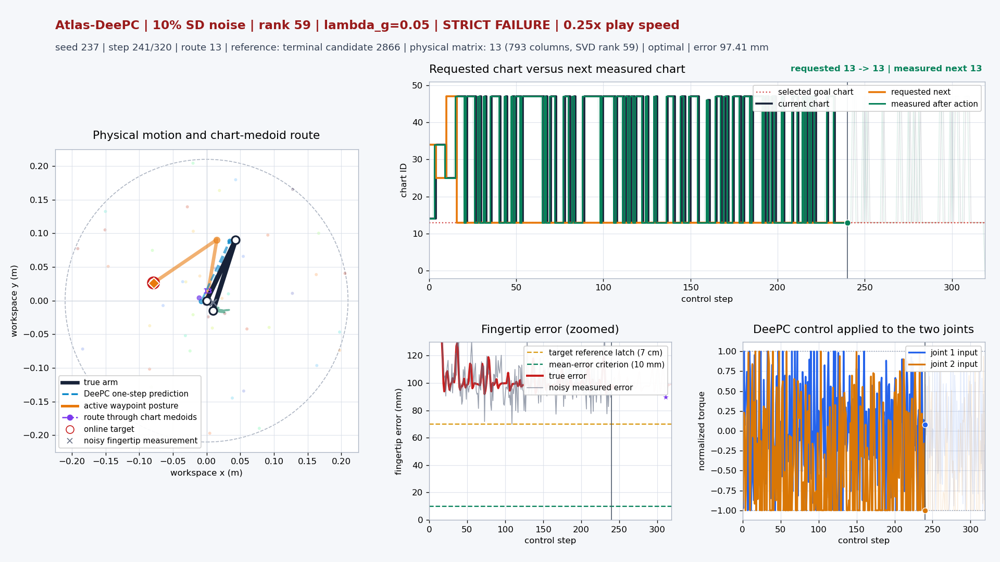

In [12]:
import base64
from candidate_goal_routing_experiment import file_digest
RENDER_VIDEOS = False
if RENDER_VIDEOS:
    from render_measurement_noise_videos import render_all
    render_all()
    get_ipython().run_line_magic("matplotlib", "inline")
VIDEO_DIR = RESULT_ROOT / "videos"
entries = json.loads((VIDEO_DIR / "manifest.json").read_text())
lookup = {(entry["seed"], entry["noise_sd_ratio"]): entry for entry in entries}
def noisy_video_card(seed, ratio):
    entry = lookup[seed, ratio]
    metadata = entry["metadata"]
    source_dir = RESULT_ROOT / experiment.level_name(ratio)
    source = source_dir / f"seed{seed}_control_results.npz"
    video = VIDEO_DIR / Path(entry["video"]).name
    poster = VIDEO_DIR / Path(entry["poster"]).name
    assert metadata["source_result_sha256"] == file_digest(source)
    assert metadata["source_atlas_sha256"] == file_digest(source_dir / "behavioral_atlas.npz")
    assert metadata["video_sha256"] == file_digest(video)
    assert metadata["poster_sha256"] == file_digest(poster)
    assert metadata["lam_g"] == .05 and metadata["noise_sd_ratio"] == ratio
    assert metadata["saved_control_steps"] == metadata["displayed_control_steps"] == 320
    assert metadata["true_arm_displayed"] and metadata["noisy_fingertip_displayed"]
    row = frame[(frame.seed == seed) & (frame.noise_sd_ratio == ratio)].iloc[0]
    outcome = "STRICT SUCCESS" if row.strict_success else "FAILED STRICT TEST"
    color = "#087443" if row.strict_success else "#B42318"
    mp4 = base64.b64encode(video.read_bytes()).decode("ascii")
    png = base64.b64encode(poster.read_bytes()).decode("ascii")
    return (f'<div style="min-width:0;background:white;color:#172238;padding:12px;border:1px solid #cbd5e1">'
        f'<h3 style="margin:0 0 8px;color:#172238">Seed {seed} | {100*ratio:g}% SD noise</h3>'
        f'<p style="margin:0 0 8px;color:{color}">{outcome}</p>'
        f'<p style="margin:0 0 8px;color:#344054">Final-100 true error: mean {1000*row.mean_last_100:.3f} mm; '
        f'maximum {1000*row.max_last_100:.3f} mm</p>'
        f'<video controls preload="none" style="width:100%" poster="data:image/png;base64,{png}" '
        f'src="data:video/mp4;base64,{mp4}"></video></div>')
for seed, lower, higher in ((212, .01, .05), (222, .01, .05), (237, .02, .10)):
    display(HTML('<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,520px),1fr));gap:14px;margin-bottom:20px">'
                 + noisy_video_card(seed, lower) + noisy_video_card(seed, higher) + '</div>'))


## 7. Rank-62 Ablation on the Same Noisy Data

**Seven noise levels, 100 paired seeds per level (211--310).** This section changes
only the retained linear-subspace rank from **59 to 62**. Clarabel,
$\lambda_g=0.05$, all other QP settings, N=10 iterative terminal selection,
graph waypoints, 320-step rollouts, and evaluation thresholds remain unchanged.

For each noise level, reuse its already fitted noisy K-means atlas, medoids, and
transition graph. Reconstruct exactly the same noisy Hankel matrix and compute
rank-62 bases. The first 59 basis directions and their empirical bounds are
checked against the saved rank-59 cache. Online Gaussian draws and targets are
paired across ranks. Closed-loop states and chart sequences can still differ.

The chart clouds in Section 2 apply to both ranks: no second clustering is needed
when changing rank alone. Rank-62 traces and timings are saved separately; the
rank-59 results above are preserved. These are exploratory ablations on previously
inspected seeds, not a fresh held-out validation of rank selection.


In [13]:
import measurement_noise_rank62_ablation as rank62_experiment
RUN_RANK62_EXPERIMENTS = False
RANK62_ROOT = rank62_experiment.RESULT_ROOT
if RUN_RANK62_EXPERIMENTS:
    rank62_experiment.run_all(SD_RATIOS, SEEDS, workers=WORKERS)
rank62_payloads = {}
rank62_errors = {}
rank62_extra = []
for ratio in SD_RATIOS:
    folder = RANK62_ROOT / experiment.level_name(ratio)
    path = folder / "summary.json"
    assert path.exists(), f"Missing rank-62 panel {ratio}: enable RUN_RANK62_EXPERIMENTS."
    payload = json.loads(path.read_text())
    assert payload["version"] == rank62_experiment.VERSION and payload["seeds"] == SEEDS
    rows = payload["results"]
    assert len(rows) == 100 and {r["seed"] for r in rows} == set(SEEDS)
    assert all(r["svd_rank"] == 62 and r["lam_g"] == .05 and r["steps"] == 320 for r in rows)
    assert all(r["graph_waypoints_enabled"] and r["evaluation_uses_true_outputs"] for r in rows)
    assert all(r["candidate_count"] == 10 and r["clusters"] == 48 for r in rows)
    assert all(not r["fitted_dynamics_model"] and not r["feedback_fallback"] and not r["noise_on_inputs"] for r in rows)
    assert all(r["minimum_selected_goal_source_separation"] >= .06 for r in rows)
    artifact = payload["artifact"]
    assert artifact["same_chart_memberships_and_graph_verified"]
    assert artifact["nested_basis_prefix_verified"]
    old_folder = RESULT_ROOT / experiment.level_name(ratio)
    old_artifact = payloads[ratio]["artifact"]
    assert artifact["signature"]["rank59_artifact_manifest_sha256"] == file_digest(old_folder / "artifact_manifest.json")
    previous_config = dict(old_artifact["signature"]["config"])
    current_config = dict(artifact["signature"]["config"])
    assert previous_config.pop("svd_rank") == 59 and current_config.pop("svd_rank") == 62
    assert previous_config == current_config
    for name, digest in artifact["artifact_sha256"].items():
        assert file_digest(folder / name) == digest
    with np.load(folder / "behavioral_atlas.npz", allow_pickle=True) as current:
        with np.load(old_folder / "behavioral_atlas.npz", allow_pickle=True) as previous:
            for key in previous.files:
                if key != "config":
                    np.testing.assert_array_equal(current[key], previous[key])
    with np.load(folder / "chart_cache.npz") as current:
        with np.load(old_folder / "chart_cache.npz") as previous:
            assert current["basis"].shape == (48, 144, 62)
            np.testing.assert_allclose(current["basis"][:, :, :59], previous["basis"], rtol=1e-10, atol=1e-10)
            for name in ("g_min", "g_max"):
                np.testing.assert_allclose(current[name][:, :59], previous[name], rtol=1e-10, atol=1e-10)
    for row in rows:
        seed = row["seed"]
        filename = f"seed{seed}_control_results.npz"
        with np.load(folder / filename, allow_pickle=True) as current:
            with np.load(old_folder / filename, allow_pickle=True) as previous:
                old_row = json.loads(previous["summary"].item())
                np.testing.assert_array_equal(row["exact_target_xy"], old_row["exact_target_xy"])
                np.testing.assert_array_equal(current["sensor_true"][0], previous["sensor_true"][0])
                np.testing.assert_allclose(current["sensor_measured"]-current["sensor_true"],
                    previous["sensor_measured"]-previous["sensor_true"], rtol=0, atol=1e-13)
            distance = np.asarray(current["distance"])
            np.testing.assert_allclose(distance, np.linalg.norm(current["y"][:, 6:8]-row["exact_target_xy"], axis=1))
            for window in (30, 100):
                tail = distance[-window:]
                assert row[f"success_{window}"] == bool(tail.mean() < .01 and tail.max() < .02)
            error = 1000*distance
            rank62_errors[ratio, seed] = error.copy()
        tail = error[-100:]
        rank62_extra.append({"noise_sd_ratio": ratio, "seed": seed,
            "tail_rmse_mm": np.sqrt(np.mean(tail**2)), "tail_std_mm": tail.std(),
            "tail_p95_mm": np.quantile(tail, .95), "tail_within_10_pct": 100*np.mean(tail < 10),
            "tail_within_20_pct": 100*np.mean(tail < 20)})
    rank62_payloads[ratio] = payload
rank62_frame = pd.DataFrame([r for p in rank62_payloads.values() for r in p["results"]])
rank62_frame["strict_success"] = rank62_frame.success_30 & rank62_frame.success_100
rank62_frame = rank62_frame.merge(pd.DataFrame(rank62_extra), on=["noise_sd_ratio", "seed"], validate="one_to_one")
print(f"Verified {len(rank62_frame)} rank-62 rollouts: same atlases, nested bases, targets, initial states, and noise streams.")


Verified 700 rank-62 rollouts: same atlases, nested bases, targets, initial states, and noise streams.


### 7.1. Paired Success and True Fingertip Error

Every seed contributes equally. Success still requires mean error below 10 mm and
maximum error below 20 mm in both final-30 and final-100 windows. Repaired and
regressed counts compare the same seed and noise realization, not unpaired totals.


Successes       Median final-100 mean error (mm)          \
Rank                59    62                               59      62   
Noise SD (%)                                                            
0.0               97.0  97.0                            2.045   1.911   
1.0               88.0  93.0                            3.163   2.825   
2.0               87.0  90.0                            4.660   4.416   
3.0               60.0  76.0                            7.532   6.089   
4.0               62.0  63.0                            7.643   8.133   
5.0               41.0  31.0                           10.599  12.080   
10.0               2.0   2.0                           16.468  18.078   

             P90 final-100 mean error (mm)          
Rank                                    59      62  
Noise SD (%)                                        
0.0                                  4.431   4.358  
1.0                                 10.640   6.104  
2.0                                 10.198   8.950  
3.0                                 17.639  18.147  
4.0                                 15.340  15.213  
5.0                                 21.122  22.112  
10.0                                30.721  34.795

,Repaired by rank 62,Regressed at rank 62,Net repaired,Median paired mean-error change (mm)
Noise SD (%),,,,
0.0,0,0,0,-0.095
1.0,6,1,5,-0.240
2.0,5,2,3,-0.123
3.0,18,2,16,-0.384
4.0,7,6,1,0.182
5.0,4,14,-10,0.503
10.0,1,1,0,0.981


,,Successes,Trials,Success rate (%),Median final-100 mean error (mm),P90 final-100 mean error (mm),Median tail RMSE (mm),Median within-seed tail SD (mm),Mean tail time below 10 mm (%),Unsolved QP steps
Rank,Noise SD (%),,,,,,,,,
59,0.0,97,100,97.0,2.045,4.431,2.045,0.000,97.00,0
62,0.0,97,100,97.0,1.911,4.358,1.911,0.000,97.00,0
59,1.0,88,100,88.0,3.163,10.640,3.260,0.864,89.28,0
62,1.0,93,100,93.0,2.825,6.104,2.911,0.641,92.96,0
59,2.0,87,100,87.0,4.660,10.198,4.789,1.181,87.77,0
62,2.0,90,100,90.0,4.416,8.950,4.841,1.154,89.86,0
59,3.0,60,100,60.0,7.532,17.639,7.983,2.064,63.51,0
62,3.0,76,100,76.0,6.089,18.147,6.298,1.584,75.93,0
59,4.0,62,100,62.0,7.643,15.340,8.355,2.239,66.06,0


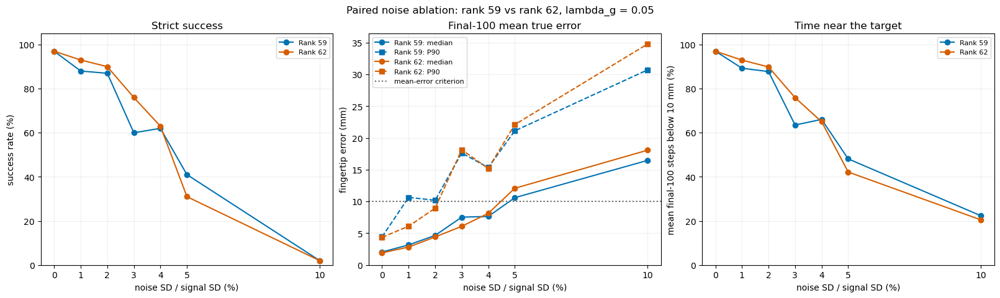

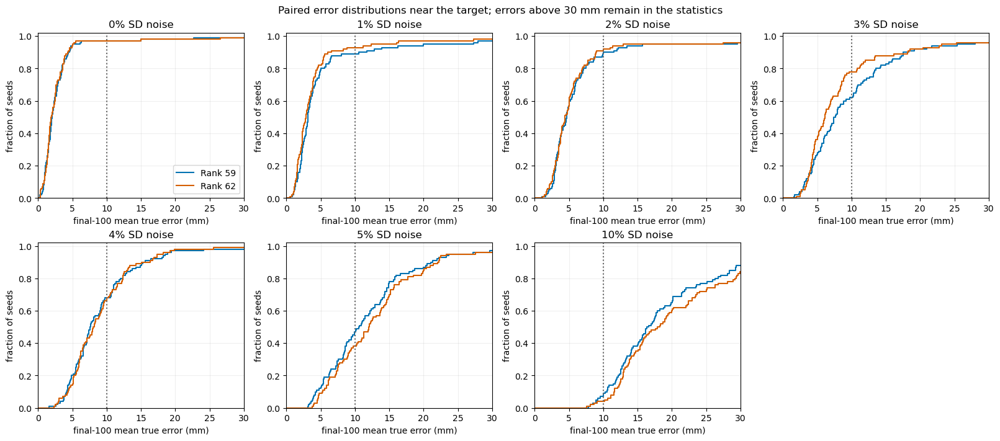

In [14]:
rank_rows = []
rank_pair_rows = []
for ratio in SD_RATIOS:
    for rank, data in [(59, frame), (62, rank62_frame)]:
        rows = data[data.noise_sd_ratio == ratio]
        rank_rows.append({"Rank": rank, "Noise SD (%)": 100*ratio,
            "Successes": int(rows.strict_success.sum()), "Trials": len(rows),
            "Success rate (%)": 100*rows.strict_success.mean(),
            "Median final-100 mean error (mm)": 1000*rows.mean_last_100.median(),
            "P90 final-100 mean error (mm)": 1000*rows.mean_last_100.quantile(.9),
            "Median tail RMSE (mm)": rows.tail_rmse_mm.median(),
            "Median within-seed tail SD (mm)": rows.tail_std_mm.median(),
            "Mean tail time below 10 mm (%)": rows.tail_within_10_pct.mean(),
            "Unsolved QP steps": int(rows.unsolved_steps.sum())})
    first = frame[frame.noise_sd_ratio == ratio].set_index("seed").loc[SEEDS]
    second = rank62_frame[rank62_frame.noise_sd_ratio == ratio].set_index("seed").loc[SEEDS]
    repaired = second.index[~first.strict_success & second.strict_success].tolist()
    regressed = second.index[first.strict_success & ~second.strict_success].tolist()
    rank_pair_rows.append({"Noise SD (%)": 100*ratio, "Repaired by rank 62": len(repaired),
        "Regressed at rank 62": len(regressed), "Net repaired": len(repaired)-len(regressed),
        "Median paired mean-error change (mm)": 1000*(second.mean_last_100-first.mean_last_100).median(),
        "Repaired seeds": repaired, "Regressed seeds": regressed})
rank_summary = pd.DataFrame(rank_rows)
rank_pairs = pd.DataFrame(rank_pair_rows).set_index("Noise SD (%)")
display(rank_summary.pivot(index="Noise SD (%)", columns="Rank",
    values=["Successes", "Median final-100 mean error (mm)", "P90 final-100 mean error (mm)"]).round(3))
display(rank_pairs.drop(columns=["Repaired seeds", "Regressed seeds"]).round(3))
display(HTML("<details><summary>Full rank-62 summary and paired seed lists</summary>"
    + rank_summary.set_index(["Rank", "Noise SD (%)"]).round(3).to_html()
    + rank_pairs.to_html() + "</details>"))
(RANK62_ROOT / "rank_comparison_report.json").write_text(rank_summary.to_json(orient="records", indent=2))
(RANK62_ROOT / "paired_rank_report.json").write_text(rank_pairs.reset_index().to_json(orient="records", indent=2))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.7), constrained_layout=True)
for rank, color in [(59, "#0072B2"), (62, "#D55E00")]:
    rows = rank_summary[rank_summary.Rank == rank]
    axes[0].plot(rows["Noise SD (%)"], rows["Success rate (%)"], "o-", color=color, label=f"Rank {rank}")
    axes[1].plot(rows["Noise SD (%)"], rows["Median final-100 mean error (mm)"], "o-", color=color,
                 label=f"Rank {rank}: median")
    axes[1].plot(rows["Noise SD (%)"], rows["P90 final-100 mean error (mm)"], "s--", color=color,
                 label=f"Rank {rank}: P90")
    axes[2].plot(rows["Noise SD (%)"], rows["Mean tail time below 10 mm (%)"], "o-", color=color, label=f"Rank {rank}")
axes[0].set(title="Strict success", ylabel="success rate (%)", ylim=(0, 105))
axes[1].set(title="Final-100 mean true error", ylabel="fingertip error (mm)", ylim=(0, None))
axes[1].axhline(10, color="#666666", linestyle=":", label="mean-error criterion")
axes[2].set(title="Time near the target", ylabel="mean final-100 steps below 10 mm (%)", ylim=(0, 105))
for ax in axes:
    ax.set_xlabel("noise SD / signal SD (%)")
    ax.set_xticks(percent)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle("Paired noise ablation: rank 59 vs rank 62, lambda_g = 0.05")
fig.savefig(RANK62_ROOT / "rank_comparison_success_error.png", dpi=170)
plt.show()
fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for ax, ratio in zip(axes.flat, SD_RATIOS):
    for rank, data, color in [(59, frame, "#0072B2"), (62, rank62_frame, "#D55E00")]:
        values = np.sort(1000*data.loc[data.noise_sd_ratio == ratio, "mean_last_100"].to_numpy())
        ax.step(np.r_[0, values], np.r_[0, np.arange(1, len(values)+1)/len(values)],
                where="post", color=color, label=f"Rank {rank}")
    ax.axvline(10, color="#666666", linestyle=":")
    ax.set(xlim=(0, 30), ylim=(0, 1.02), title=f"{100*ratio:g}% SD noise",
           xlabel="final-100 mean true error (mm)", ylabel="fraction of seeds")
    ax.grid(alpha=.2)
axes.flat[0].legend()
for ax in list(axes.flat)[len(SD_RATIOS):]:
    ax.set_visible(False)
fig.suptitle("Paired error distributions near the target; errors above 30 mm remain in the statistics")
fig.savefig(RANK62_ROOT / "rank_comparison_error_cdf.png", dpi=170)
plt.show()


### 7.2. Rank-62 Trajectories Near the Criterion

The same twelve fixed seeds and seven noise levels as the rank-59 section above.
The zoom retains a 0--30 mm vertical range; triangles flag samples outside it.
The second figure retains the full error range. All errors are unsmoothed simulator
truth and all 320 control steps contribute to the saved results.


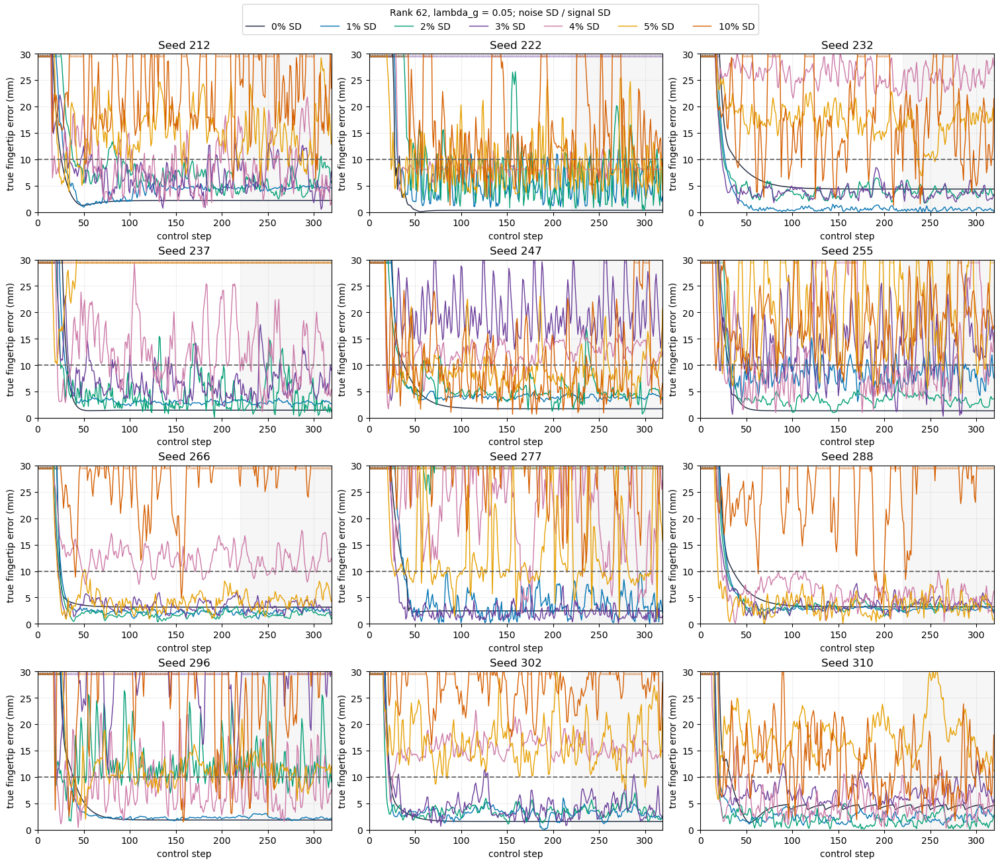

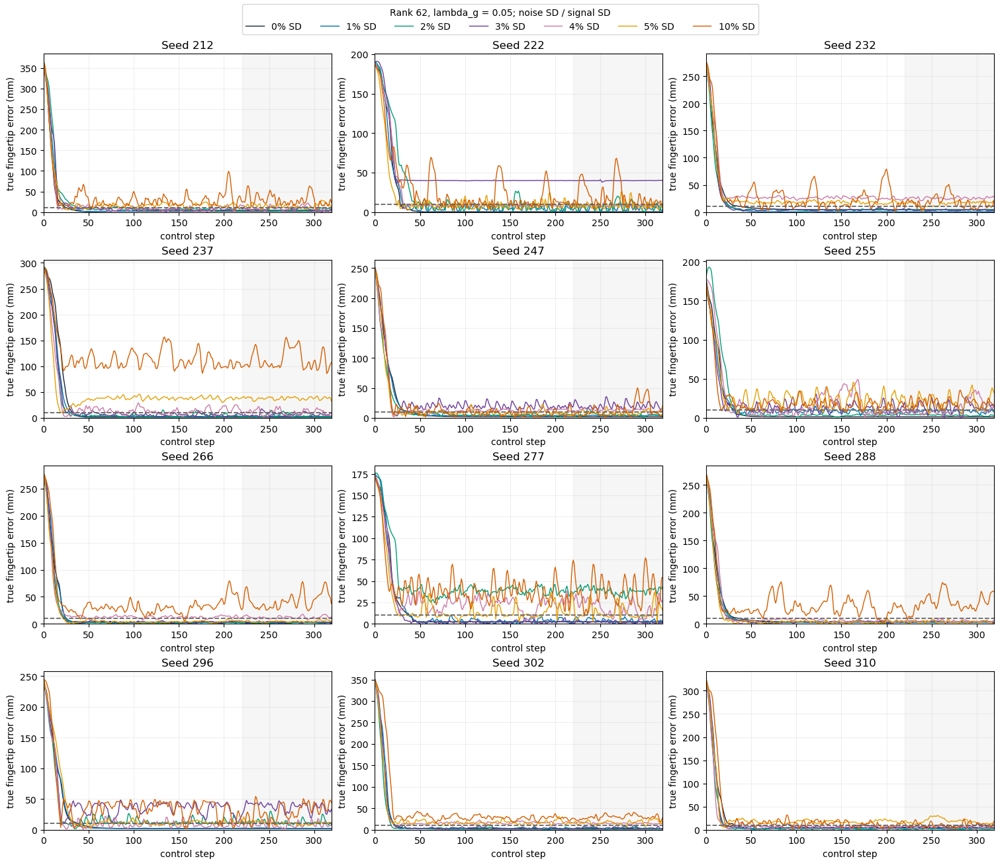

In [15]:
for zoom in (True, False):
    fig, axes = plt.subplots(4, 3, figsize=(15, 13), constrained_layout=True)
    for ax, seed in zip(axes.flat, EXAMPLE_SEEDS):
        for ratio, color in zip(SD_RATIOS, COLORS):
            error = rank62_errors[ratio, seed]
            ax.plot(error, color=color, linewidth=1, label=f"{100*ratio:g}% SD")
            if zoom:
                outside = np.flatnonzero(error > 30)
                ax.scatter(outside, np.full(len(outside), 29.6), marker="^", s=8, color=color, alpha=.25, linewidths=0)
        ax.axvspan(220, 319, color="#666666", alpha=.06)
        ax.axhline(10, color="#666666", linestyle="--", linewidth=1.3)
        ax.set(ylim=(0, 30) if zoom else (0, None), xlim=(0, 319), title=f"Seed {seed}",
               xlabel="control step", ylabel="true fingertip error (mm)")
        ax.grid(alpha=.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=len(SD_RATIOS),
               title="Rank 62, lambda_g = 0.05; noise SD / signal SD")
    suffix = "zoom" if zoom else "full"
    fig.savefig(RANK62_ROOT / f"rank62_noise_example_traces_{suffix}.png", dpi=150)
    plt.show()


### 7.3. Computation Time by Module

Same timing definitions as rank 59: four rollout workers, one numerical-library
thread per worker, first five steps excluded, no dedicated warm-up. QP time
includes construction and solve; simulator stepping and sensor-noise generation
are excluded. Rank panels were measured in separate batches on a shared computer,
so these timings do not isolate the causal effect of rank on runtime.

Means are stacked because they add. Median and p99 module values are not stacked.
Offline clustering is reused from rank 59, while rank-62 basis construction is
performed separately and is not charged to each online control step.


mean_ms         median_ms           p99_ms         
Rank              59      62        59      62       59       62
Noise SD (%)                                                    
0.0           37.852  47.653    34.574  43.605   80.605   98.702
1.0           40.582  49.233    36.346  45.177   97.267  100.988
2.0           39.449  52.360    36.099  45.886   88.416  128.337
3.0           46.859  56.257    44.122  40.802   86.769  264.519
4.0           46.489  40.374    43.879  36.009   85.733   95.732
5.0           40.520  37.546    36.408  34.622   99.482   68.968
10.0          42.756  38.499    38.244  35.245  106.572   78.777

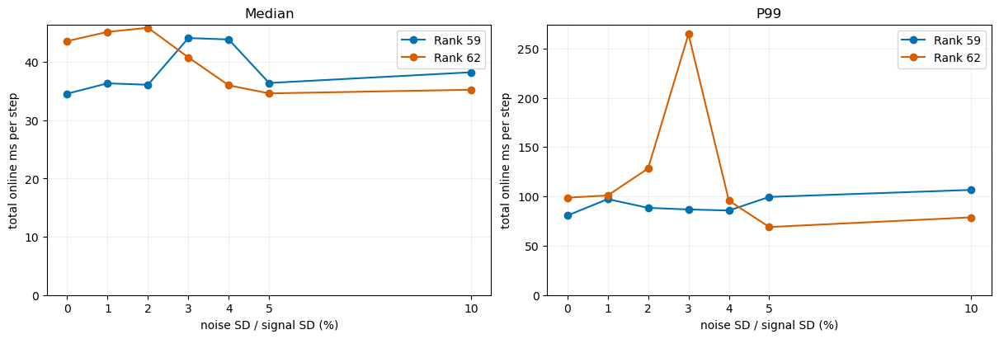

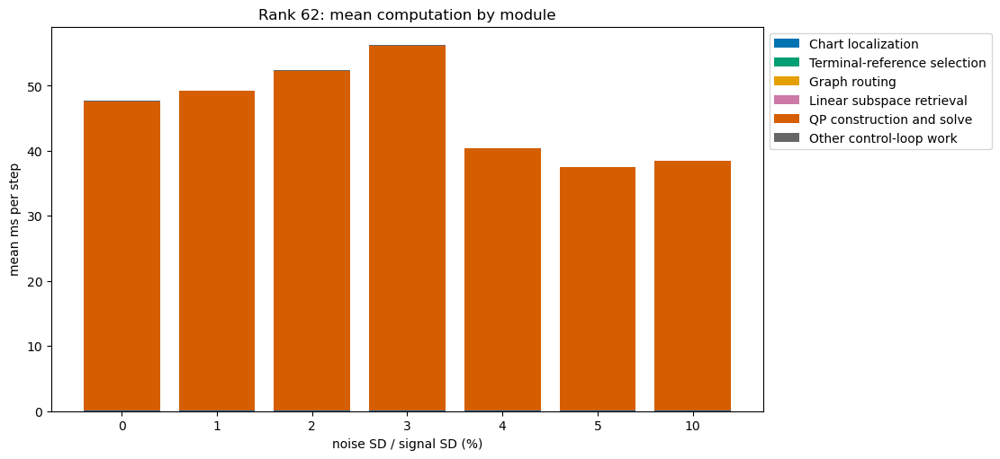

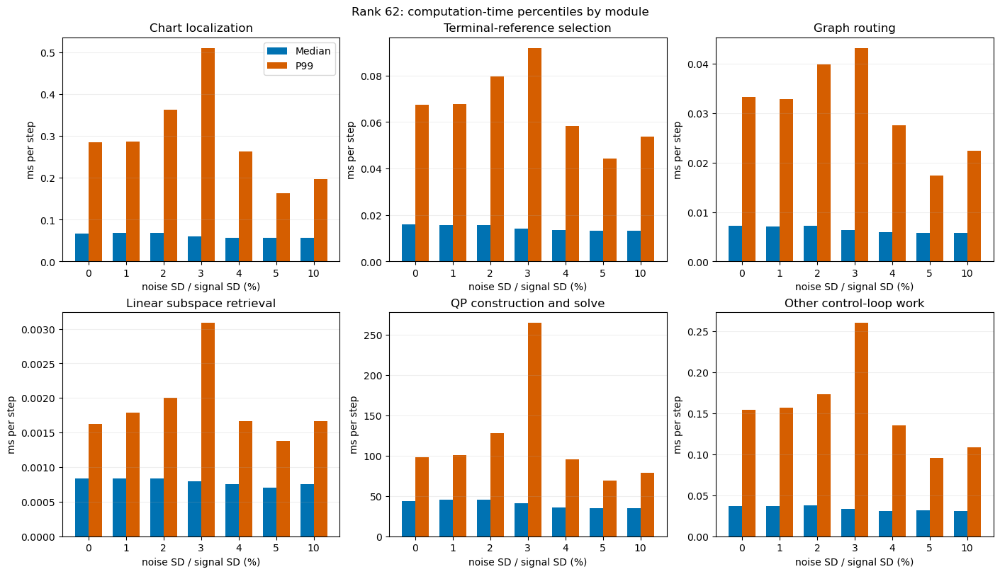

,Rank-62 offline bases/routes (s),One-time goal setup median (ms)
Noise SD (%),,
0.0,0.191,14.407
1.0,0.176,13.571
2.0,0.173,14.771
3.0,0.183,16.565
4.0,0.140,13.968
5.0,0.144,5.516
10.0,0.146,6.749


In [16]:
rank_timing_rows = []
for rank, collection in [(59, payloads), (62, rank62_payloads)]:
    for ratio in SD_RATIOS:
        assert collection[ratio]["timing"]["timed_steps"] == 31500
        rank_timing_rows.extend({"Rank": rank, "Noise SD (%)": 100*ratio, **r}
                               for r in collection[ratio]["timing"]["modules"])
rank_timing = pd.DataFrame(rank_timing_rows)
display(rank_timing[rank_timing.module == "Total online control"].pivot(
    index="Noise SD (%)", columns="Rank", values=["mean_ms", "median_ms", "p99_ms"]).round(3))
display(HTML("<details><summary>All timing modules for both ranks</summary>"
    + rank_timing.set_index(["Rank", "Noise SD (%)", "module"])[["mean_ms", "median_ms", "p95_ms", "p99_ms"]]
      .round(4).to_html() + "</details>"))
(RANK62_ROOT / "rank_comparison_timing.json").write_text(rank_timing.to_json(orient="records", indent=2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, metric, title in zip(axes, ["median_ms", "p99_ms"], ["Median", "P99"]):
    for rank, color in [(59, "#0072B2"), (62, "#D55E00")]:
        rows = rank_timing[(rank_timing.Rank == rank) & (rank_timing.module == "Total online control")]
        ax.plot(rows["Noise SD (%)"], rows[metric], "o-", color=color, label=f"Rank {rank}")
    ax.set(ylim=(0, None), title=title, ylabel="total online ms per step", xlabel="noise SD / signal SD (%)")
    ax.set_xticks(percent)
    ax.grid(alpha=.2)
    ax.legend()
fig.savefig(RANK62_ROOT / "rank_comparison_timing.png", dpi=170)
plt.show()
rank62_timing = rank_timing[rank_timing.Rank == 62]
rank_modules = [m for m in rank62_timing.module.unique() if m != "Total online control"]
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
bottom = np.zeros(len(SD_RATIOS))
for module, color in zip(rank_modules, module_colors):
    values = rank62_timing[rank62_timing.module == module].set_index("Noise SD (%)").loc[percent, "mean_ms"].to_numpy()
    ax.bar(np.arange(len(SD_RATIOS)), values, bottom=bottom, color=color, label=module)
    bottom += values
ax.set(ylim=(0, None), ylabel="mean ms per step", xlabel="noise SD / signal SD (%)", title="Rank 62: mean computation by module")
ax.set_xticks(np.arange(len(SD_RATIOS)), [f"{x:g}" for x in percent])
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.savefig(RANK62_ROOT / "rank62_mean_timing_modules.png", dpi=170)
plt.show()
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for ax, module in zip(axes.flat, rank_modules):
    rows = rank62_timing[rank62_timing.module == module].set_index("Noise SD (%)").loc[percent]
    ax.bar(np.arange(len(SD_RATIOS))-.18, rows.median_ms, width=.36, color="#0072B2", label="Median")
    ax.bar(np.arange(len(SD_RATIOS))+.18, rows.p99_ms, width=.36, color="#D55E00", label="P99")
    ax.set(ylim=(0, None), title=module, ylabel="ms per step", xlabel="noise SD / signal SD (%)")
    ax.set_xticks(np.arange(len(SD_RATIOS)), [f"{x:g}" for x in percent])
    ax.grid(axis="y", alpha=.2)
axes.flat[0].legend()
fig.suptitle("Rank 62: computation-time percentiles by module")
fig.savefig(RANK62_ROOT / "rank62_timing_module_percentiles.png", dpi=170)
plt.show()
display(pd.DataFrame([{"Noise SD (%)": 100*r,
                      "Rank-62 offline bases/routes (s)": rank62_payloads[r]["artifact"]["offline_preparation_s"]["svd_cache_and_routes"],
                      "One-time goal setup median (ms)": rank62_payloads[r]["timing"]["one_time_goal_setup_ms"]["median"]}
                     for r in SD_RATIOS]).set_index("Noise SD (%)").round(3))


## 8. Reproduction and Preservation

From the project root, using the existing environment:

```bash
python src/measurement_noise_rank59_ablation.py --workers 4 --ratios 0 0.01 0.02 0.03 0.04 0.05 0.10
python src/render_measurement_noise_videos.py --workers 2
```

Completed levels/seeds are resumed; incompatible artifact settings are rejected.
The notebook defaults to reading saved results with rank 59 and coefficient
regularization 0.05. This override is local to the noise experiment; other baseline notebooks
are not changed. No duplicate full Hankel matrices
are saved: noise is regenerated deterministically, while atlases and reduced bases
are cached. Baseline data, notebooks, and results remain unchanged.

This combined ablation does not isolate offline versus online noise. It does not
establish robustness to correlated noise, sensor bias, encoder noise before output
lifting, process disturbances, or independently repeated offline datasets.
Noise also affects the posture retrieved for terminal-reference augmentation:
its fingertip entries are replaced with the exact target as in the baseline,
but its joint entries remain noisy. Consequently, results include reference
inconsistency as well as changes in localization and behavioral prediction.
The previous rank-60, lambda_g=0 notebook is preserved in
`archive/notebooks/ablation_measurement_noise_rank60_lamg0_before_rank59.ipynb`.
Its data remain in their original directory. The new experiment uses a separate
`measurement_noise_rank59_lamg005_100_v1` directory and does not overwrite old results.

Rank 62 is an additional paired section, not a replacement for rank 59.
Its seven-level panel can be resumed with:

```bash
python src/measurement_noise_rank62_ablation.py --workers 4
```

Rank-62 outputs are stored in `measurement_noise_rank62_lamg005_100_v1`.
The six videos in Section 6 remain the rank-59 diagnostics.
